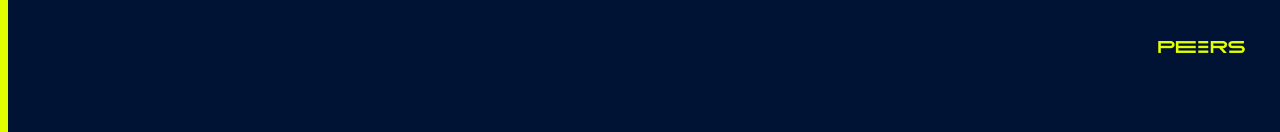

# **Análise Diagnóstica do Case OrbitShop**
Este notebook apresenta a auditoria de dados e a análise diagnóstica da OrbitShop (jan/2023 a dez/2024), desenvolvida para investigar as divergências na taxa de cancelamento e identificar os principais gargalos operacionais e comerciais da operação com base nos dados fornecidos.

**Autora:** Caroline Yumi Nomura

**Entrada:** `Base_Dados_OrbitShop.xlsx`



## 1. Bibliotecas e preparação da base de dados



In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

caminho = 'Base_Dados_OrbitShop.xlsx'

db = pd.read_excel(caminho, sheet_name=None)

df_clientes = db['Clientes']
df_produtos = db['Produtos']
df_pedidos = db['Pedidos']
df_itens_pedido = db['Itens_Pedido']
df_tickets_suporte = db['Tickets_Suporte']
df_avaliacoes = db['Avaliacoes']

df_pedidos['data_pedido'] = pd.to_datetime(df_pedidos['data_pedido'])
df_clientes['data_cadastro'] = pd.to_datetime(df_clientes['data_cadastro'])
df_tickets_suporte['data_abertura'] = pd.to_datetime(df_tickets_suporte['data_abertura'])
df_tickets_suporte['data_resolucao'] = pd.to_datetime(df_tickets_suporte['data_resolucao'])

## 2. **Q2** - Distribuição de status dos pedidos

### 2.1. Checagem de integridade e valores ausentes




In [41]:
# Valida unicidade do ID, ausência de nulos e padronização em status
assert df_pedidos['id'].is_unique, 'IDs duplicados encontrados.'
assert (
    df_pedidos['status'].notna().all()
), 'Valores nulos encontrados em status.'
assert (
    df_pedidos['status'].nunique()
    == df_pedidos['status'].str.strip().str.lower().nunique()
), 'Variações de grafia em status.'

# Valores ausentes por coluna
display(
    pd.DataFrame({
        'nulos': df_pedidos.isna().sum(),
        'pct_nulos (%)': (df_pedidos.isna().mean() * 100).round(2),
    })
)

,nulos,pct_nulos (%)
id,0,0.00
cliente_id,0,0.00
data_pedido,0,0.00
status,0,0.00
valor_total,79,0.53
canal_venda,0,0.00
cupom_desconto,0,0.00


Foram identificados 79 pedidos com `valor_total` nulo.

Para entender melhor a distribuição de nulos do `valor_total` por status, criamos uma tabela auxiliar com esses dados.

In [42]:
tabela_nulos = (
    df_pedidos.assign(valor_nulo=df_pedidos['valor_total'].isna())
    .groupby('status', dropna=False)
    .agg(
        total_pedidos=('status', 'size'),
        qtd_nulos=('valor_nulo', 'sum'),
    )
    .reset_index()
)

tabela_nulos['pct_nulos_no_status (%)'] = (
    tabela_nulos['qtd_nulos'] / tabela_nulos['total_pedidos'] * 100
).round(2)

tabela_nulos['distribuicao_dos_nulos (%)'] = (
    tabela_nulos['qtd_nulos'] / tabela_nulos['qtd_nulos'].sum() * 100
).round(2)

display(tabela_nulos.sort_values(by='qtd_nulos', ascending=False))

,status,total_pedidos,qtd_nulos,pct_nulos_no_status (%),distribuicao_dos_nulos (%)
3,entregue,9959,58,0.58,73.42
0,cancelado,2537,11,0.43,13.92
2,em_transito,1371,6,0.44,7.59
1,devolvido,1133,4,0.35,5.06


Os nulos por status são 58 em entregue, 11 em cancelado, 6 em em_transito e 4 em devolvido. Isso dá entre 0,35% e 0,58% de cada status. Como os nulos não estão concentrados em nenhum status, vamos mantê-los como `NaN`.

Consequência em cada cálculo da tabela da seção 2.6:
* **Contagem de pedidos:** usa `size`, que conta todas as linhas de cada status, inclusive as com `valor_total` vazio. Os 15.000 pedidos entram na tabela e nos percentuais de pedidos.
* **Valor dos pedidos:** a soma de `valor_total` ignora os `NaN`, então os 79 pedidos sem valor não contribuem para o total.
* **Ticket médio:** a média de `valor_total` também ignora os `NaN`, então é calculada só sobre os pedidos com valor informado. Isso evita que os nulos puxem o ticket para baixo.


### 2.2. Tabela de distribuição por status, receita e ticket médio

In [43]:
tab = (
    df_pedidos.groupby('status')
    .agg(
        Pedidos=('status', 'size'),
        Valor_mi=('valor_total', 'sum'),
        Ticket_medio=('valor_total', 'mean'),
    )
    .sort_values('Pedidos', ascending=False)
)

tab['% Pedidos'] = (tab['Pedidos'] / tab['Pedidos'].sum() * 100).round(1)
tab['% Receita'] = (tab['Valor_mi'] / tab['Valor_mi'].sum() * 100).round(1)
tab['Valor total (R$ mi)'] = (tab['Valor_mi'] / 1e6).round(2)
tab['Ticket médio (R$)'] = tab['Ticket_medio'].round(0)

tab = tab[[
    'Pedidos',
    '% Pedidos',
    'Valor total (R$ mi)',
    '% Receita',
    'Ticket médio (R$)',
]]

total_row = pd.DataFrame(
    {
        'Pedidos': [tab['Pedidos'].sum()],
        '% Pedidos': [100.0],
        'Valor total (R$ mi)': [tab['Valor total (R$ mi)'].sum().round(2)],
        '% Receita': [100.0],
        'Ticket médio (R$)': [df_pedidos['valor_total'].mean().round(0)],
    },
    index=['Total'],
)

tab_exibicao = pd.concat([tab, total_row])
tab_exibicao.index.name = 'Status'

display(
    tab_exibicao.style.format({
        'Pedidos': '{:,.0f}',
        '% Pedidos': '{:.1f}%',
        'Valor total (R$ mi)': 'R$ {:.2f}',
        '% Receita': '{:.1f}%',
        'Ticket médio (R$)': 'R$ {:,.0f}',
    })
)

,Pedidos,% Pedidos,Valor total (R$ mi),% Receita,Ticket médio (R$)
Status,,,,,
entregue,"9,959",66.4%,R$ 25.44,66.2%,"R$ 2,569"
cancelado,"2,537",16.9%,R$ 6.65,17.3%,"R$ 2,631"
em_transito,"1,371",9.1%,R$ 3.51,9.1%,"R$ 2,575"
devolvido,"1,133",7.6%,R$ 2.82,7.3%,"R$ 2,499"
Total,"15,000",100.0%,R$ 38.42,100.0%,"R$ 2,575"


### 2.3. Gráfico de distribuição de pedidos por status

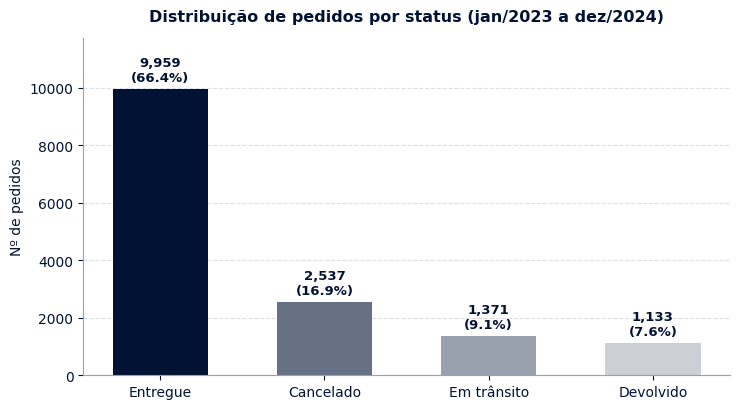

In [44]:
cores = ['#011334', '#677185', '#99A1AE', '#CCD0D6']
labels_map = {
    'entregue': 'Entregue',
    'cancelado': 'Cancelado',
    'em_transito': 'Em trânsito',
    'devolvido': 'Devolvido',
}

# Recalcula localmente para evitar dependência de estado global
tab_status = (
    df_pedidos.groupby('status')
    .agg(Pedidos=('status', 'size'))
    .sort_values('Pedidos', ascending=False)
)
tot_pedidos = tab_status['Pedidos'].sum()
labels_x = [labels_map.get(s, s) for s in tab_status.index]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar(
    labels_x,
    tab_status['Pedidos'],
    color=cores[: len(tab_status)],
    width=0.58,
)

for b in bars:
  h = b.get_height()
  pct = (h / tot_pedidos) * 100
  ax.text(
      b.get_x() + b.get_width() / 2,
      h + 180,
      f'{h:,.0f}\n({pct:.1f}%)',
      ha='center',
      va='bottom',
      fontsize=9.5,
      fontweight='bold',
      color='#011334',
  )

ax.set_title(
    'Distribuição de pedidos por status (jan/2023 a dez/2024)',
    fontsize=11.5,
    fontweight='bold',
    color='#011334',
    pad=12,
)
ax.set_ylabel('Nº de pedidos', color='#011334')
ax.set_ylim(0, tab_status['Pedidos'].max() * 1.18)

# Acabamento limpo
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#99A1AE')
ax.tick_params(colors='#011334')
ax.grid(axis='y', linestyle='--', alpha=0.35, color='#99A1AE')
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('q2_pedidos_por_status.png', dpi=150)
plt.show()

### 2.4. Aprofundamento: estabilidade anual e gargalo trimestral

In [45]:
# 1. Comparativo anual de status
ano_qtd = pd.crosstab(df_pedidos['data_pedido'].dt.year, df_pedidos['status'])
ano_pct = (ano_qtd.div(ano_qtd.sum(axis=1), axis=0) * 100).round(1)

print('Volume por ano:')
display(ano_qtd)
print('\nParticipação (%) por ano:')
display(ano_pct)

print('\nEvolução trimestral de pedidos em trânsito vs. tickets de suporte:')
# 2. Evolução trimestral de pedidos em trânsito
tri_ped = df_pedidos['data_pedido'].dt.to_period('Q').astype(str).str.replace('Q', '-Q')
tri_tkt = pd.to_datetime(df_tickets_suporte['data_abertura']).dt.to_period('Q').astype(str).str.replace('Q', '-Q')

tab_trimestre = (
    df_pedidos.assign(Trimestre=tri_ped)
    .groupby('Trimestre')
    .agg(
        Pedidos=('id', 'count'),
        Em_transito=('status', lambda s: (s == 'em_transito').sum()),
    )
)

tab_trimestre['% em trânsito'] = (
    tab_trimestre['Em_transito'] / tab_trimestre['Pedidos'] * 100
).round(1)

tab_trimestre['Tickets abertos'] = (
    df_tickets_suporte.assign(Trimestre=tri_tkt)
    .groupby('Trimestre')['id']
    .count()
)

tab_trimestre['% tickets / pedidos'] = (
    tab_trimestre['Tickets abertos'] / tab_trimestre['Pedidos'] * 100
).round(1)

display(tab_trimestre)

Volume por ano:


status,cancelado,devolvido,em_transito,entregue
data_pedido,,,,
2023,1407,633,788,5558
2024,1130,500,583,4401



Participação (%) por ano:


status,cancelado,devolvido,em_transito,entregue
data_pedido,,,,
2023,16.8,7.5,9.4,66.3
2024,17.1,7.6,8.8,66.5



Evolução trimestral de pedidos em trânsito vs. tickets de suporte:


,Pedidos,Em_transito,% em trânsito,Tickets abertos,% tickets / pedidos
Trimestre,,,,,
2023-Q1,1630,148,9.1,350,21.5
2023-Q2,1674,142,8.5,458,27.4
2023-Q3,1653,162,9.8,449,27.2
2023-Q4,3429,336,9.8,922,26.9
2024-Q1,1592,153,9.6,377,23.7
2024-Q2,1664,146,8.8,469,28.2
2024-Q3,1708,139,8.1,474,27.8
2024-Q4,1650,145,8.8,501,30.4


### 2.5. Observações
1. **Perda efetiva de quase 1 em cada 4 pedidos:** Apenas 66,4% dos pedidos foram concluídos como `entregue` (9.959). Somando `cancelado` (16,9%; 2.537 pedidos) e `devolvido` (7,6%; 1.133 pedidos), 24,5% da operação (3.670 pedidos) não se converteu em venda, representando cerca de R\$ 9,47 milhões em receita perdida.
2. **Estabilidade na taxa anual de cancelamento:** A taxa de cancelamento ficou praticamente estável entre 2023 (16,8%) e 2024 (17,1%), enquanto o volume absoluto caiu 19,7% (de 1.407 para 1.130). Esse resultado não confirma com exatidão nem a alta de 40% citada por Camila (Head de Growth) nem a queda de 18% para 16% citada por Rogério (CFO), sugerindo que os relatórios das áreas usam critérios distintos (como incluir devoluções, pedidos travados ou recortes específicos) e é necessário saber deles como os dados estão sendo calculados em seus relatórios. O que se pode dizer olhando para essa análise é que o dado da Camila está muito mais distante da taxa encontrada do que o de Rogério.
3. **Pedidos antigos ainda em trânsito e reflexo no ticket de suporte:** Dos 1.371 pedidos (9,1%) ainda marcados como `em_transito`, 788 são de 2023. Embora o volume absoluto atinja 336 pedidos no 4º trimestre de 2023, ele acompanha proporcionalmente a alta de vendas do período (~9% a 10% dos pedidos do trimestre), enquanto os chamados de suporte saltaram no mesmo intervalo (922 tickets). A permanência desse status em pedidos de 2023–2024 indica falha de atualização sistêmica (falta de baixa de entrega/cancelamento) ou extravios não encerrados.
4. **Limitações da base:** A base não tem data de atualização de status, então só é possível ver a data do pedido, e não quando os pedidos `em_transito` pararam de ser atualizados. Isso impede distinguir entre status desatualizado e pedidos realmente extraviados.

## 3. **Q3** - Desempenho por categoria: receita vs. volume

Nesta seção, cruzamos os itens de pedido com o catálogo de produtos para comparar o ranking das categorias em faturamento e unidades vendidas, verificando se as duas listas coincidem e o que explica as divergências.

### 3.1. Checagem de integridade, valores ausentes e regra de receita

Antes de agregar os resultados, validamos as chaves entre `Itens_Pedido`, `Produtos` e `Pedidos`, mapeamos nulos e verificamos se `preco_praticado` já incorpora o desconto aplicado.

In [46]:
# Validações de unicidade, chaves estrangeiras e valores válidos
assert df_produtos['id'].is_unique, 'IDs de produtos duplicados.'
assert df_itens_pedido['id'].is_unique, 'IDs de itens duplicados.'
assert df_itens_pedido['produto_id'].isin(df_produtos['id']).all(), 'produto_id inválido.'
assert df_itens_pedido['pedido_id'].isin(df_pedidos['id']).all(), 'pedido_id inválido.'
assert (df_itens_pedido['quantidade'] > 0).all(), 'Quantidade <= 0.'
assert (df_itens_pedido['preco_praticado'] > 0).all(), 'Preço praticado <= 0.'
assert df_produtos['categoria'].notna().all(), 'Categoria nula.'
assert (
    df_produtos['categoria'].nunique()
    == df_produtos['categoria'].str.strip().str.lower().nunique()
), 'Variações de grafia em categoria.'

# Checagem de nulos em Itens_Pedido
display(
    pd.DataFrame({
        'nulos': df_itens_pedido.isna().sum(),
        'pct_nulos (%)': (df_itens_pedido.isna().mean() * 100).round(2),
    })
)

# Verificação da regra de preço líquido: preco_praticado == preco_unitario * (1 - desconto)
teste_preco = (
    df_itens_pedido.merge(
        df_produtos[['id', 'preco_unitario']],
        left_on='produto_id',
        right_on='id',
        how='left',
    )
    .dropna(subset=['desconto_aplicado'])
)
preco_esperado = teste_preco['preco_unitario'] * (1 - teste_preco['desconto_aplicado'])
bate = (teste_preco['preco_praticado'] - preco_esperado).abs() <= 0.02

print(
    f"Itens com preco_praticado líquido confirmado: {bate.mean():.1%} (n = {len(teste_preco):,})"
)

,nulos,pct_nulos (%)
id,0,0.00
pedido_id,0,0.00
produto_id,0,0.00
quantidade,0,0.00
preco_praticado,0,0.00
desconto_aplicado,301,0.82


Itens com preco_praticado líquido confirmado: 100.0% (n = 36,439)


**Regra de receita:** Em 100% dos registros com desconto preenchido, `preco_praticado` já reflete o valor líquido após o desconto (`preco_unitario × (1 - desconto)`). Assim, a receita do item é `quantidade × preco_praticado` (evitando duplo desconto), e os 301 itens (0,82%) com `desconto_aplicado` nulo não afetam o cálculo.

**Recorte principal:** Excluímos os pedidos `cancelado` (que não geraram venda efetiva) e mantemos os demais (incluindo `devolvido`, cuja venda ocorreu antes da reversão). Na seção 3.4, vamos testar a estabilidade do ranking sob outros recortes.

### 3.2. Tabela: Desempenho por categoria (Receita vs. Volume)

In [47]:
# Monta base consolidada de itens
itens = (
    df_itens_pedido.merge(
        df_produtos[['id', 'categoria']].rename(columns={'id': 'produto_id'}),
        on='produto_id',
        how='left',
        validate='many_to_one',
    )
    .merge(
        df_pedidos[['id', 'status']].rename(columns={'id': 'pedido_id'}),
        on='pedido_id',
        how='left',
        validate='many_to_one',
    )
)
itens['receita_item'] = itens['quantidade'] * itens['preco_praticado']

# Base principal: pedidos não cancelados
vendas = itens[itens['status'] != 'cancelado']


def resumo_categorias(base):
  t = base.groupby('categoria').agg(
      Receita=('receita_item', 'sum'),
      Unidades=('quantidade', 'sum'),
      Pedidos=('pedido_id', 'nunique'),
  )
  t['Rank receita'] = t['Receita'].rank(ascending=False).astype(int)
  t['Rank volume'] = t['Unidades'].rank(ascending=False).astype(int)
  return t


tab = resumo_categorias(vendas).sort_values('Receita', ascending=False)
tab['Receita (R$ mi)'] = (tab['Receita'] / 1e6).round(2)
tab['% Receita'] = (tab['Receita'] / tab['Receita'].sum() * 100).round(1)
tab['% Unidades'] = (tab['Unidades'] / tab['Unidades'].sum() * 100).round(1)
tab['Preço médio/un. (R$)'] = (tab['Receita'] / tab['Unidades']).round(0)
tab['Coincide'] = np.where(
    tab['Rank receita'] == tab['Rank volume'], 'Sim', 'Não'
)

tab_exibe = tab[[
    'Receita (R$ mi)',
    '% Receita',
    'Rank receita',
    'Unidades',
    '% Unidades',
    'Rank volume',
    'Coincide',
    'Preço médio/un. (R$)',
    'Pedidos',
]]
tab_exibe.index.name = 'Categoria'

display(
    tab_exibe.style.format({
        'Receita (R$ mi)': 'R$ {:.2f}',
        '% Receita': '{:.1f}%',
        'Unidades': '{:,.0f}',
        '% Unidades': '{:.1f}%',
        'Preço médio/un. (R$)': 'R$ {:,.0f}',
        'Pedidos': '{:,.0f}',
    })
)

,Receita (R$ mi),% Receita,Rank receita,Unidades,% Unidades,Rank volume,Coincide,Preço médio/un. (R$),Pedidos
Categoria,,,,,,,,,
Eletrônicos,R$ 27.25,18.5%,1,"15,521",17.0%,1,Sim,"R$ 1,756","4,316"
Casa & Decoração,R$ 21.81,14.8%,2,"14,850",16.2%,2,Sim,"R$ 1,469","4,175"
Beleza & Saúde,R$ 20.84,14.2%,3,"11,507",12.6%,4,Não,"R$ 1,811","3,370"
Esporte & Lazer,R$ 18.07,12.3%,4,"10,214",11.2%,5,Não,"R$ 1,769","3,039"
Moda,R$ 17.52,11.9%,5,"12,943",14.1%,3,Não,"R$ 1,353","3,698"
Livros & Papelaria,R$ 16.23,11.0%,6,"9,093",9.9%,6,Sim,"R$ 1,785","2,767"
Bebês & Crianças,R$ 13.50,9.2%,7,"8,672",9.5%,8,Não,"R$ 1,557","2,609"
Alimentos & Bebidas,R$ 11.74,8.0%,8,"8,691",9.5%,7,Não,"R$ 1,351","2,603"


### 3.3. Gráfico: Receita vs. Volume por categoria

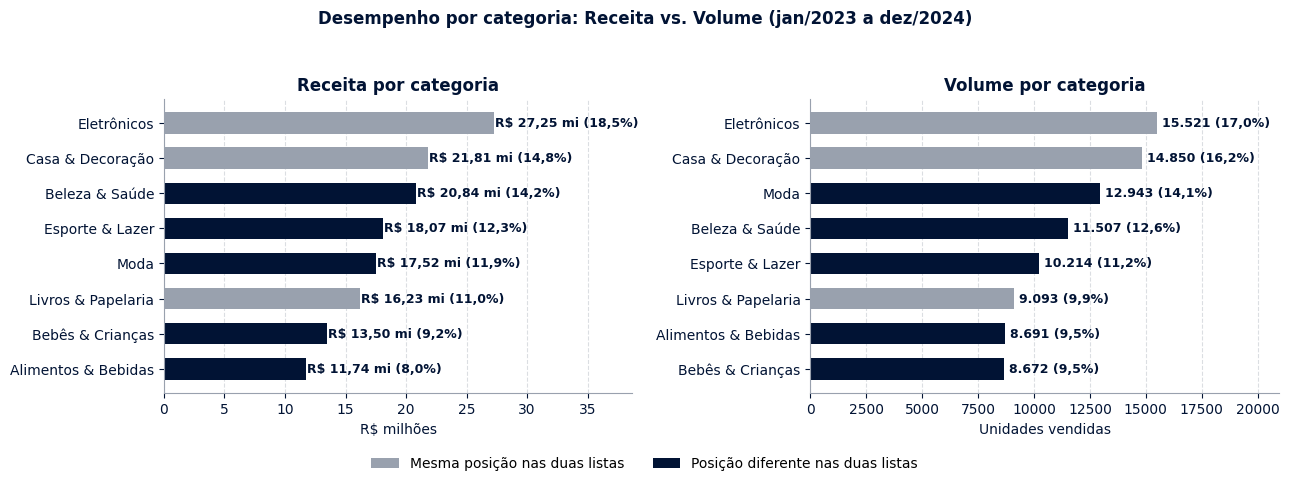

In [48]:
def br(x, casas=0):
  return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


mudou = tab['Rank receita'] != tab['Rank volume']
cor_igual = '#99A1AE'
cor_mudou = '#011334'

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Painel 1: Receita
d_rec = tab.sort_values('Receita', ascending=False)
axes[0].barh(
    d_rec.index,
    d_rec['Receita (R$ mi)'],
    color=[cor_mudou if mudou[c] else cor_igual for c in d_rec.index],
    height=0.62,
)
for y, (v, p) in enumerate(zip(d_rec['Receita (R$ mi)'], d_rec['% Receita'])):
  axes[0].text(
      v + 0.08,
      y,
      f'R$ {br(v, 2)} mi ({br(p, 1)}%)',
      va='center',
      fontsize=9,
      color='#011334',
      fontweight='bold',
  )
axes[0].set_title('Receita por categoria', fontweight='bold', color='#011334')
axes[0].set_xlabel('R$ milhões', color='#011334')
axes[0].set_xlim(0, d_rec['Receita (R$ mi)'].max() * 1.42)

# Painel 2: Volume
d_vol = tab.sort_values('Unidades', ascending=False)
axes[1].barh(
    d_vol.index,
    d_vol['Unidades'],
    color=[cor_mudou if mudou[c] else cor_igual for c in d_vol.index],
    height=0.62,
)
for y, (v, p) in enumerate(zip(d_vol['Unidades'], d_vol['% Unidades'])):
  axes[1].text(
      v + 220,
      y,
      f'{br(v)} ({br(p, 1)}%)',
      va='center',
      fontsize=9,
      color='#011334',
      fontweight='bold',
  )
axes[1].set_title('Volume por categoria', fontweight='bold', color='#011334')
axes[1].set_xlabel('Unidades vendidas', color='#011334')
axes[1].set_xlim(0, d_vol['Unidades'].max() * 1.35)

for ax in axes:
  ax.invert_yaxis()
  ax.spines[['top', 'right']].set_visible(False)
  ax.spines[['left', 'bottom']].set_color('#99A1AE')
  ax.tick_params(colors='#011334')
  ax.grid(axis='x', linestyle='--', alpha=0.35, color='#99A1AE')
  ax.set_axisbelow(True)

fig.legend(
    handles=[
        Patch(facecolor=cor_igual, label='Mesma posição nas duas listas'),
        Patch(facecolor=cor_mudou, label='Posição diferente nas duas listas'),
    ],
    loc='lower center',
    ncol=2,
    frameon=False,
)
fig.suptitle(
    'Desempenho por categoria: Receita vs. Volume (jan/2023 a dez/2024)',
    fontsize=12,
    fontweight='bold',
    color='#011334',
)
plt.tight_layout(rect=(0, 0.06, 1, 0.94))
plt.savefig('q3_categorias_receita_volume.png', dpi=150)
plt.show()

### 3.4. Testando se o ranking muda conforme o recorte de status

In [49]:
bases = {
    'Todos os pedidos': itens,
    'Sem cancelados (principal)': vendas,
    'Sem cancelados e devolvidos': itens[~itens['status'].isin(['cancelado', 'devolvido'])],
    'Somente entregues': itens[itens['status'] == 'entregue'],
}

resumos = {nome: resumo_categorias(b) for nome, b in bases.items()}
rank_receita = pd.DataFrame({n: r['Rank receita'] for n, r in resumos.items()}).loc[d_rec.index]
rank_volume = pd.DataFrame({n: r['Rank volume'] for n, r in resumos.items()}).loc[d_vol.index]

print(
    f"Ranking de receita idêntico nas 4 bases? {rank_receita.nunique(axis=1).eq(1).all()} | "
    f"Ranking de volume idêntico nas 4 bases? {rank_volume.nunique(axis=1).eq(1).all()}"
)
display(rank_receita.add_prefix('Rec: ').join(rank_volume.add_prefix('Vol: ')))

Ranking de receita idêntico nas 4 bases? True | Ranking de volume idêntico nas 4 bases? True


,Rec: Todos os pedidos,Rec: Sem cancelados (principal),Rec: Sem cancelados e devolvidos,Rec: Somente entregues,Vol: Todos os pedidos,Vol: Sem cancelados (principal),Vol: Sem cancelados e devolvidos,Vol: Somente entregues
Categoria,,,,,,,,
Eletrônicos,1,1,1,1,1,1,1,1
Casa & Decoração,2,2,2,2,2,2,2,2
Beleza & Saúde,3,3,3,3,4,4,4,4
Esporte & Lazer,4,4,4,4,5,5,5,5
Moda,5,5,5,5,3,3,3,3
Livros & Papelaria,6,6,6,6,6,6,6,6
Bebês & Crianças,7,7,7,7,8,8,8,8
Alimentos & Bebidas,8,8,8,8,7,7,7,7


Os rankings de receita e volume permanecem idênticos em todos os recortes testados (base total, sem cancelados, sem cancelados/devolvidos e somente entregues). Então, podemos descartar a possibilidade da diferença das listas ser causada por algum desses fatores.

### 3.5. Observações

1. **O topo coincide, mas as listas divergem nas posições intermediárias:** Eletrônicos (18,5% da receita; 17,0% das unidades) e Casa & Decoração (14,8% e 16,2%) lideram ambos os rankings igualmente, e Livros & Papelaria fecha em 8º nos dois. Nas posições intermediárias, porém, as listas não coincidem.
2. **Inversão entre Moda e Beleza & Saúde:** Moda ocupa a 3ª posição em volume (12.943 unidades; 14,1%), mas cai para 5ª em receita (11,9%). Beleza & Saúde faz o movimento inverso: 3ª em receita (14,2%) e 4ª em volume (12,6%). Esporte & Lazer também troca de posição (4ª em receita vs. 5ª em volume).
3. **O preço médio por unidade explica a divergência:** Como `Receita = Unidades * Preço médio/un.`, categorias de ticket unitário mais baixo tem bom desempenho em volume, porém perdem em faturamento. Moda e Alimentos & Bebidas operam em torno de R\$ 1.350/un. (cerca de 16% abaixo da média geral de R\$ 1.606/un.), enquanto Beleza & Saúde atinge R\$ 1.811/un. (13% acima da média). Pensando logicamente esses dados fazem sentido, pois itens como roupas e alimentos geralmente são mais baratos que artigos de beleza e saúde.

## 4. **Q4** - Desempenho por canal de aquisição: cancelamento e ticket médio

Nesta seção, avaliamos se algum canal de aquisição apresenta taxa de cancelamento ou ticket médio distinto dos demais, verificando se o comportamento persiste entre segmentos (B2B/B2C) e qual é o impacto financeiro desse desvio.

* **Taxa de cancelamento:** pedidos com `status = 'cancelado'` divididos pelo total de pedidos do canal.
* **Ticket médio:** média de `valor_total` por canal (desconsiderando os 79 pedidos sem valor informado, conforme padrão da Q2).

### 4.1. Checagem de integridade e preparação da base

In [50]:
# Validações de integridade e chaves entre Clientes e Pedidos
assert df_clientes['id'].is_unique, 'IDs de clientes duplicados.'
assert (
    df_pedidos['cliente_id'].isin(df_clientes['id']).all()
), 'cliente_id inválido em Pedidos.'
assert (
    df_clientes['canal_aquisicao'].notna().all()
), 'Clientes sem canal de aquisição.'
assert (
    df_clientes['canal_aquisicao'].nunique()
    == df_clientes['canal_aquisicao'].str.strip().str.lower().nunique()
), 'Variações de grafia em canal_aquisicao.'

# Cruza pedidos com canal de aquisição e segmento do cliente
pedidos_canal = df_pedidos.merge(
    df_clientes[['id', 'canal_aquisicao', 'segmento']].rename(
        columns={'id': 'cliente_id'}
    ),
    on='cliente_id',
    how='left',
    validate='many_to_one',
)
pedidos_canal['cancelado'] = pedidos_canal['status'] == 'cancelado'
pedidos_canal['ano'] = pedidos_canal['data_pedido'].dt.year

sem_pedido = (~df_clientes['id'].isin(df_pedidos['cliente_id'])).sum()
print(
    f'Base validada: {len(pedidos_canal):,} pedidos | '
    f'Clientes sem pedidos (excluídos da análise por pedido): {sem_pedido}'
)

Base validada: 15,000 pedidos | Clientes sem pedidos (excluídos da análise por pedido): 23


### 4.2. Tabela de cancelamento e ticket por canal de aquisição

In [51]:
tab_canal = (
    pedidos_canal.groupby('canal_aquisicao')
    .agg(
        Clientes=('cliente_id', 'nunique'),
        Pedidos=('id', 'count'),
        Cancelados=('cancelado', 'sum'),
        Ticket_medio=('valor_total', 'mean'),
        Ticket_mediano=('valor_total', 'median'),
    )
    .sort_values('Cancelados', ascending=False)
)

tab_canal['% Pedidos'] = (
    tab_canal['Pedidos'] / tab_canal['Pedidos'].sum() * 100
).round(1)
tab_canal['Taxa cancelamento (%)'] = (
    tab_canal['Cancelados'] / tab_canal['Pedidos'] * 100
).round(1)
tab_canal['Ticket médio (R$)'] = tab_canal['Ticket_medio'].round(0)
tab_canal['Ticket mediano (R$)'] = tab_canal['Ticket_mediano'].round(0)

tab_canal = tab_canal.sort_values('Taxa cancelamento (%)', ascending=False)

tab_exibe = tab_canal[[
    'Clientes',
    'Pedidos',
    '% Pedidos',
    'Cancelados',
    'Taxa cancelamento (%)',
    'Ticket médio (R$)',
    'Ticket mediano (R$)',
]]
tab_exibe.index.name = 'Canal de aquisição'

display(
    tab_exibe.style.format({
        'Clientes': '{:,.0f}',
        'Pedidos': '{:,.0f}',
        '% Pedidos': '{:.1f}%',
        'Cancelados': '{:,.0f}',
        'Taxa cancelamento (%)': '{:.1f}%',
        'Ticket médio (R$)': 'R$ {:,.0f}',
        'Ticket mediano (R$)': 'R$ {:,.0f}',
    })
)

,Clientes,Pedidos,% Pedidos,Cancelados,Taxa cancelamento (%),Ticket médio (R$),Ticket mediano (R$)
Canal de aquisição,,,,,,,
paid_search,761,"3,965",26.4%,"1,219",30.7%,"R$ 2,554","R$ 1,546"
indicação,735,"3,658",24.4%,453,12.4%,"R$ 2,566","R$ 1,490"
orgânico,724,"3,616",24.1%,426,11.8%,"R$ 2,521","R$ 1,519"
redes_sociais,757,"3,761",25.1%,439,11.7%,"R$ 2,657","R$ 1,543"


### 4.3. Gráfico comparativo: taxa de cancelamento e ticket médio por canal

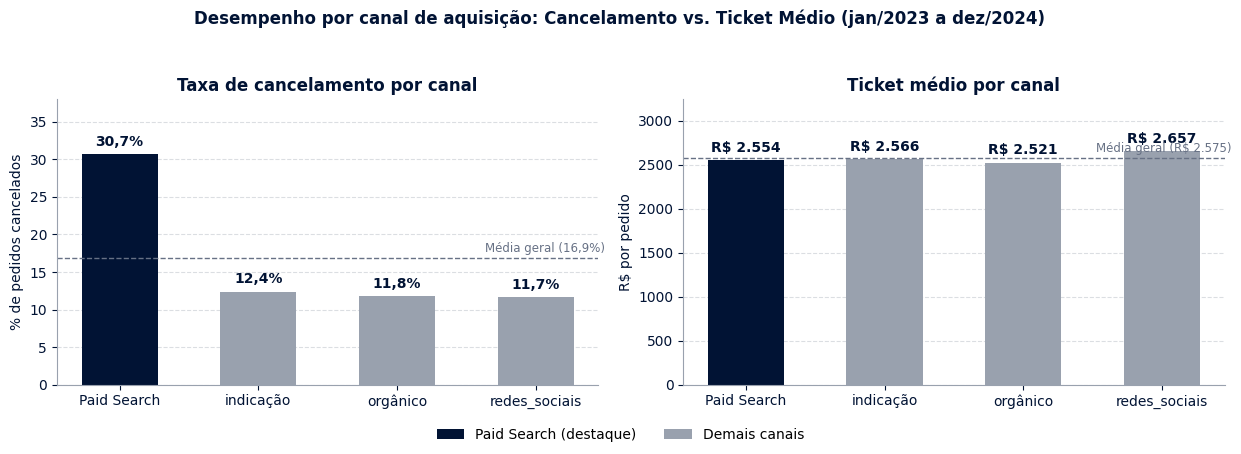

In [52]:
def br(x, casas=0):
  return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


labels_canal = {
    'paid_search': 'Paid Search',
    'organic': 'Orgânico',
    'social': 'Redes Sociais',
    'referral': 'Indicação',
}
nomes_x = [labels_canal.get(c, c) for c in tab_canal.index]
cores = [
    '#011334' if c == 'paid_search' else '#99A1AE' for c in tab_canal.index
]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

# Painel 1: Taxa de cancelamento
taxa = tab_canal['Taxa cancelamento (%)']
media_cancel = pedidos_canal['cancelado'].mean() * 100
bars1 = axes[0].bar(nomes_x, taxa, color=cores, width=0.55)
for b, v in zip(bars1, taxa):
  axes[0].text(
      b.get_x() + b.get_width() / 2,
      v + 0.7,
      f'{br(v, 1)}%',
      ha='center',
      va='bottom',
      fontweight='bold',
      color='#011334',
  )
axes[0].axhline(media_cancel, color='#677185', linestyle='--', linewidth=1)
axes[0].text(
    len(nomes_x) - 0.5,
    media_cancel + 0.7,
    f'Média geral ({br(media_cancel, 1)}%)',
    ha='right',
    fontsize=8.5,
    color='#677185',
)
axes[0].set_title(
    'Taxa de cancelamento por canal', fontweight='bold', color='#011334'
)
axes[0].set_ylabel('% de pedidos cancelados', color='#011334')
axes[0].set_ylim(0, 38)

# Painel 2: Ticket médio
ticket = tab_canal['Ticket médio (R$)']
media_ticket = pedidos_canal['valor_total'].mean()
bars2 = axes[1].bar(nomes_x, ticket, color=cores, width=0.55)
for b, v in zip(bars2, ticket):
  axes[1].text(
      b.get_x() + b.get_width() / 2,
      v + 60,
      f'R$ {br(v)}',
      ha='center',
      va='bottom',
      fontweight='bold',
      color='#011334',
  )
axes[1].axhline(media_ticket, color='#677185', linestyle='--', linewidth=1)
axes[1].text(
    len(nomes_x) - 0.5,
    media_ticket + 65,
    f'Média geral (R$ {br(media_ticket)})',
    ha='right',
    fontsize=8.5,
    color='#677185',
)
axes[1].set_title(
    'Ticket médio por canal', fontweight='bold', color='#011334'
)
axes[1].set_ylabel('R$ por pedido', color='#011334')
axes[1].set_ylim(0, ticket.max() * 1.22)

for ax in axes:
  ax.spines[['top', 'right']].set_visible(False)
  ax.spines[['left', 'bottom']].set_color('#99A1AE')
  ax.tick_params(colors='#011334')
  ax.grid(axis='y', linestyle='--', alpha=0.35, color='#99A1AE')
  ax.set_axisbelow(True)

fig.legend(
    handles=[
        Patch(facecolor='#011334', label='Paid Search (destaque)'),
        Patch(facecolor='#99A1AE', label='Demais canais'),
    ],
    loc='lower center',
    ncol=2,
    frameon=False,
)
fig.suptitle(
    'Desempenho por canal de aquisição: Cancelamento vs. Ticket Médio (jan/2023 a dez/2024)',
    fontsize=12,
    fontweight='bold',
    color='#011334',
)
plt.tight_layout(rect=(0, 0.06, 1, 0.94))
plt.savefig('q4_canal_aquisicao.png', dpi=150)
plt.show()

### 4.4. Validação estatística, controle de variáveis e impacto financeiro

Para garantir que o alto cancelamento do `paid_search` não seja ruído amostral nem reflexo de outra variável (como concentração de clientes B2B, uso de cupons ou poucos clientes recorrentes), aplicamos testes de hipótese e comparamos o comportamento por segmento e cliente:

* **Teste Qui-quadrado ($\chi^2$):** verifica se a diferença nas *taxas de cancelamento* entre canais é real ou fruto do acaso ($p < 0{,}05$ indica diferença estatisticamente significativa).
* **ANOVA e Kruskal-Wallis:** verificam se o *ticket médio/mediano* difere de forma relevante entre os canais ($p > 0{,}05$ indica estabilidade entre grupos).

In [53]:
# Testes estatisticos
p_cancel_todos = stats.chi2_contingency(
    pd.crosstab(pedidos_canal['canal_aquisicao'], pedidos_canal['cancelado'])
)[1]

outros = pedidos_canal[pedidos_canal['canal_aquisicao'] != 'paid_search']
p_cancel_outros = stats.chi2_contingency(
    pd.crosstab(outros['canal_aquisicao'], outros['cancelado'])
)[1]

grupos_ticket = [
    d['valor_total'].dropna() for _, d in pedidos_canal.groupby('canal_aquisicao')
]
p_ticket_anova = stats.f_oneway(*grupos_ticket)[1]
p_ticket_kruskal = stats.kruskal(*grupos_ticket)[1]

print(
    f'Cancelamento (4 canais): p = {p_cancel_todos:.2e} | '
    f'Cancelamento (3 canais sem paid_search): p = {p_cancel_outros:.2f}'
)
print(
    f'Ticket (ANOVA): p = {p_ticket_anova:.2f} | '
    f'Ticket (Kruskal-Wallis): p = {p_ticket_kruskal:.2f}\n'
)

# Controle por segmento (B2B vs B2C) e dispersão por cliente
seg_resumo = pedidos_canal.pivot_table(
    index='canal_aquisicao',
    columns='segmento',
    values='cancelado',
    aggfunc=lambda s: round(s.mean() * 100, 1),
).add_prefix('Cancel % ')

por_cli = (
    pedidos_canal.groupby(['canal_aquisicao', 'cliente_id'])
    .agg(pedidos=('id', 'count'), cancelados=('cancelado', 'sum'))
    .reset_index()
    .groupby('canal_aquisicao')
    .agg(
        Pedidos_por_cliente=('pedidos', lambda s: round(s.mean(), 1)),
        Pct_clientes_com_cancel=('cancelados', lambda s: round((s > 0).mean() * 100, 1)),
    )
)

display(seg_resumo.join(por_cli).loc[tab_canal.index])

# Quantificação do excesso de cancelamentos do paid_search
ps = pedidos_canal[pedidos_canal['canal_aquisicao'] == 'paid_search']
taxa_demais = outros['cancelado'].mean()
excesso_pedidos = ps['cancelado'].sum() - (len(ps) * taxa_demais)
ticket_cancel_ps = ps.loc[ps['cancelado'], 'valor_total'].mean()

print(
    f"Impacto Paid Search: responde por {len(ps)/len(pedidos_canal):.1%} dos pedidos e "
    f"{ps['cancelado'].sum()/pedidos_canal['cancelado'].sum():.1%} dos cancelamentos."
)
print(
    f'Excesso vs. média dos demais canais ({taxa_demais:.1%}): '
    f'~{excesso_pedidos:,.0f} pedidos (~R$ {excesso_pedidos * ticket_cancel_ps / 1e6:,.2f} mi).'
)

Cancelamento (4 canais): p = 7.22e-159 | Cancelamento (3 canais sem paid_search): p = 0.60
Ticket (ANOVA): p = 0.32 | Ticket (Kruskal-Wallis): p = 0.49



,Cancel % B2B,Cancel % B2C,Pedidos_por_cliente,Pct_clientes_com_cancel
Canal de aquisição,,,,
paid_search,32.4,30.3,5.2,80.7
indicação,11.7,12.6,5.0,45.4
orgânico,11.8,11.8,5.0,43.4
redes_sociais,12.2,11.5,5.0,42.9


Impacto Paid Search: responde por 26.4% dos pedidos e 48.0% dos cancelamentos.
Excesso vs. média dos demais canais (11.9%): ~745 pedidos (~R$ 1.96 mi).


Um p-valor abaixo de 0,05 indica diferença entre os grupos. Aqui o cancelamento difere entre os canais (p muito pequeno), mas os três canais fora do `paid_search` são estatisticamente iguais entre si. O ticket médio não difere entre os canais.

### 4.5. Observações

1. **O `paid_search` cancela 2,6x mais que os demais canais:** Apresenta taxa de cancelamento de 30,7%, contra 11,7% a 12,4% em indicação, orgânico e redes sociais ($p < 0{,}001$). Os outros três canais são estatisticamente equivalentes entre si ($p = 0{,}60$).
2. **O ticket médio não muda entre canais:** Os quatro canais operam na mesma faixa de R\$ 2.521 a R\$ 2.657 ($p = 0{,}32$), com mediana em torno de R\$ 1.500. A diferença entre média e mediana ocorre porque clientes B2B (20% dos pedidos em todos os canais) tem ticket médio de R\$ 7.800, contra R\$ 1.260 no B2C, mas dentro de cada segmento o ticket também é praticamente igual entre canais.
3. **O problema é generalizado na base do canal, não concentrado em poucos clientes ou variáveis:** O `paid_search` mantém cancelamento elevado tanto no B2B quanto no B2C, em todos os canais de venda (site, app, marketplace), com ou sem cupom e nos dois anos. Além disso, 81% dos clientes adquiridos via `paid_search` tiveram ao menos um pedido cancelado (contra 43%–45% nos demais canais), descartando distorção por poucos usuários.
4. **Alto impacto financeiro e operacional:** Embora represente 26,4% dos pedidos, o `paid_search` concentra 48,0% de todos os cancelamentos da OrbitShop. Sem ele, a taxa geral cairia de 16,9% para 11,9%; igualando sua taxa à dos demais canais.
5. **Hipótese:** Como preço, ticket e perfil de clientes são iguais aos dos outros canais, o alto cancelamento pode ser explicado pela qualidade da aquisição, ou um desalinhamento de expectativa do cliente na mídia paga (ex.: promessas comerciais/prazo nos anúncios que não se confirmam no checkout ou entrega, refletido na maior incidência de tickets de *cobrança* e *dúvida* nesse público). Recomenda-se reavaliar o Custo de Aquisição de Clientes (CAC) considerando apenas pedidos entregues e analisar as campanhas e páginas de destino de `paid_search`.

## 5. **Q5** - Variância mensal do volume de pedidos

Nesta seção, analisamos a evolução mensal do número de pedidos entre janeiro de 2023 e dezembro de 2024 para verificar se há variação sazonal, identificar os meses de pico e cruzar essas altas com canais de venda, cupons, cadastro de clientes e categorias para fundamentar uma hipótese para cada pico.

### 5.1. Checagem temporal e tabela comparativa mensal (2023 vs. 2024)



In [54]:
# Valida cobertura temporal completa dos 24 meses
assert df_pedidos['data_pedido'].notna().all(), 'Datas ausentes em Pedidos.'
meses_unicos = df_pedidos['data_pedido'].dt.to_period('M').nunique()
assert (
    meses_unicos == 24
), f'Esperados 24 meses, encontrados {meses_unicos}.'

meses_nomes = [
    'Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
    'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez',
]

piv_mensal = df_pedidos.pivot_table(
    index=df_pedidos['data_pedido'].dt.month,
    columns=df_pedidos['data_pedido'].dt.year,
    values='id',
    aggfunc='count',
)
piv_mensal.index = meses_nomes
piv_mensal.index.name = 'Mês'

piv_mensal['Total (2023–2024)'] = piv_mensal[2023] + piv_mensal[2024]
piv_mensal['Var. 2024 vs. 2023 (%)'] = (
    (piv_mensal[2024] - piv_mensal[2023]) / piv_mensal[2023] * 100
).round(1)

display(
    piv_mensal.style.format({
        2023: '{:,.0f}',
        2024: '{:,.0f}',
        'Total (2023–2024)': '{:,.0f}',
        'Var. 2024 vs. 2023 (%)': '{:+.1f}%',
    })
)

data_pedido,2023,2024,Total (2023–2024),Var. 2024 vs. 2023 (%)
Mês,,,,
Jan,525,542,"1,067",+3.2%
Fev,492,499,991,+1.4%
Mar,613,551,"1,164",-10.1%
Abr,564,558,"1,122",-1.1%
Mai,579,608,"1,187",+5.0%
Jun,531,498,"1,029",-6.2%
Jul,542,588,"1,130",+8.5%
Ago,584,599,"1,183",+2.6%
Set,527,521,"1,048",-1.1%


### 5.2. Gráfico da evolução mensal de pedidos

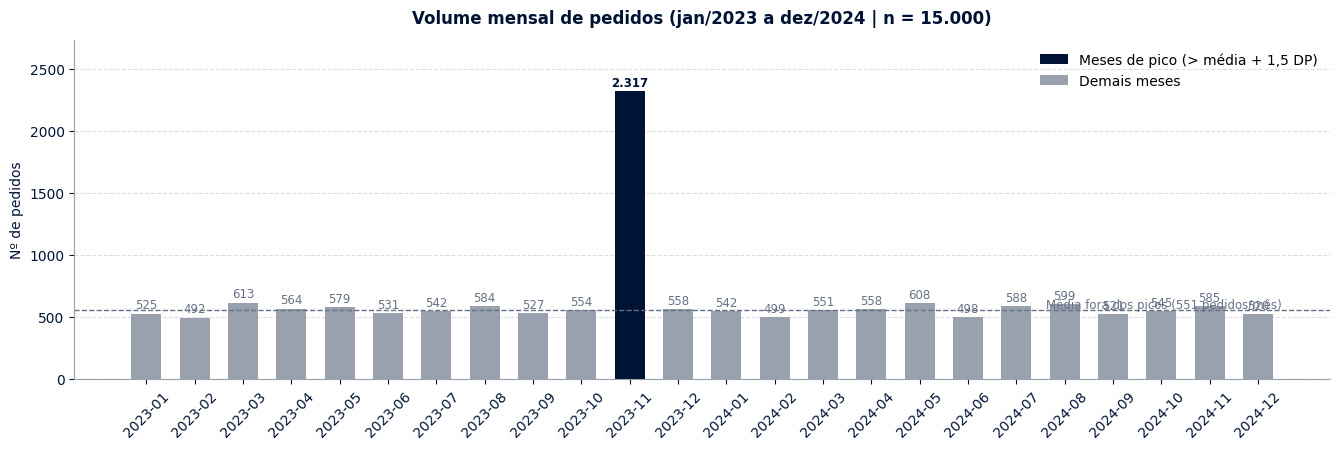

In [55]:
serie_24m = (
    df_pedidos.groupby(df_pedidos['data_pedido'].dt.to_period('M'))
    .agg(Pedidos=('id', 'count'))
    .reset_index()
)
serie_24m['ano_mes'] = serie_24m['data_pedido'].astype(str)

# Define limiar estatístico de pico (média + 1,5 desvio padrão)
limiar_pico = serie_24m['Pedidos'].mean() + 1.5 * serie_24m['Pedidos'].std()
serie_24m['is_pico'] = serie_24m['Pedidos'] > limiar_pico

cores = ['#011334' if p else '#99A1AE' for p in serie_24m['is_pico']]
media_base = serie_24m.loc[~serie_24m['is_pico'], 'Pedidos'].mean()

fig, ax = plt.subplots(figsize=(13.5, 4.6))
bars = ax.bar(serie_24m['ano_mes'], serie_24m['Pedidos'], color=cores, width=0.62)

for b, p in zip(bars, serie_24m['is_pico']):
  h = b.get_height()
  ax.text(
      b.get_x() + b.get_width() / 2,
      h + 18,
      f'{int(h):,}'.replace(',', '.'),
      ha='center',
      va='bottom',
      fontsize=8.5,
      fontweight='bold' if p else 'normal',
      color='#011334' if p else '#677185',
  )

ax.axhline(media_base, color='#677185', linestyle='--', linewidth=1)
ax.text(
    len(serie_24m) - 0.5,
    media_base + 22,
    f'Média fora dos picos ({media_base:.0f} pedidos/mês)',
    ha='right',
    fontsize=8.5,
    color='#677185',
)

ax.set_title(
    'Volume mensal de pedidos (jan/2023 a dez/2024 | n = 15.000)',
    fontsize=12,
    fontweight='bold',
    color='#011334',
    pad=12,
)
ax.set_ylabel('Nº de pedidos', color='#011334')
ax.set_ylim(0, serie_24m['Pedidos'].max() * 1.18)
ax.tick_params(axis='x', rotation=45, colors='#011334')
ax.tick_params(axis='y', colors='#011334')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#99A1AE')
ax.grid(axis='y', linestyle='--', alpha=0.35, color='#99A1AE')
ax.set_axisbelow(True)

ax.legend(
    handles=[
        Patch(facecolor='#011334', label='Meses de pico (> média + 1,5 DP)'),
        Patch(facecolor='#99A1AE', label='Demais meses'),
    ],
    frameon=False,
    loc='upper right',
)

plt.tight_layout()
plt.savefig('q5_volume_mensal_pedidos.png', dpi=150)
plt.show()

### 5.3. Gráfico da evolução diária de pedidos em novembro

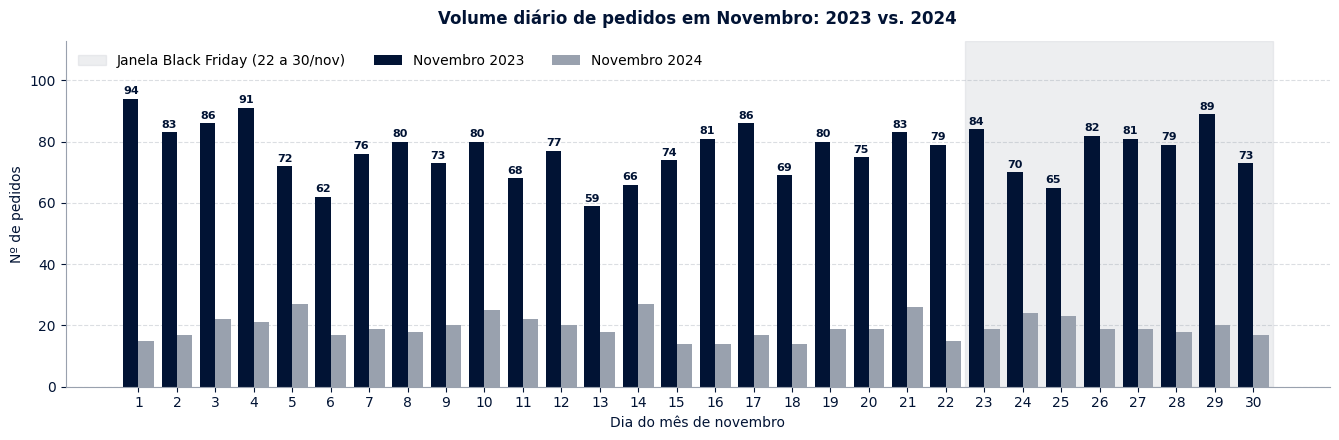

In [56]:
# Filtra apenas os pedidos de novembro (mês 11)
nov = df_pedidos[df_pedidos['data_pedido'].dt.month == 11].copy()
nov['dia'] = nov['data_pedido'].dt.day
nov['ano'] = nov['data_pedido'].dt.year

# Tabela dia (1 a 30) x ano (2023 e 2024)
piv_nov = (
    nov.pivot_table(
        index='dia', columns='ano', values='id', aggfunc='count', fill_value=0
    )
    .reindex(range(1, 31), fill_value=0)
)

dias = piv_nov.index.values
x = np.arange(len(dias))
largura = 0.40

fig, ax = plt.subplots(figsize=(13.5, 4.5))

bars_23 = ax.bar(
    x - largura / 2,
    piv_nov[2023],
    width=largura,
    label='Novembro 2023',
    color='#011334',
)
bars_24 = ax.bar(
    x + largura / 2,
    piv_nov[2024],
    width=largura,
    label='Novembro 2024',
    color='#99A1AE',
)

# Destaca faixa da semana da Black Friday (dias 22 a 30)
ax.axvspan(
    21.5,
    29.5,
    color='#CCD0D6',
    alpha=0.35,
    zorder=0,
    label='Janela Black Friday (22 a 30/nov)',
)

# Rótulos nos dias de maior volume (>= 35 pedidos no dia) para manter o gráfico limpo
for bars, cor in [(bars_23, '#011334'), (bars_24, '#677185')]:
  for b in bars:
    h = b.get_height()
    if h >= 35:
      ax.text(
          b.get_x() + b.get_width() / 2,
          h + 0.8,
          f'{int(h)}',
          ha='center',
          va='bottom',
          fontsize=8,
          fontweight='bold',
          color=cor,
      )

ax.set_title(
    'Volume diário de pedidos em Novembro: 2023 vs. 2024',
    fontsize=12,
    fontweight='bold',
    color='#011334',
    pad=12,
)
ax.set_xlabel('Dia do mês de novembro', color='#011334')
ax.set_ylabel('Nº de pedidos', color='#011334')
ax.set_xticks(x)
ax.set_xticklabels(dias)
ax.set_ylim(0, piv_nov[[2023, 2024]].max().max() * 1.2)

ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#99A1AE')
ax.tick_params(colors='#011334')
ax.grid(axis='y', linestyle='--', alpha=0.35, color='#99A1AE')
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left', ncol=3)

plt.tight_layout()
plt.savefig('q5_novembro_diario.png', dpi=150)
plt.show()

### 5.4. Diagnóstico do mês de pico

In [57]:
ped_full = df_pedidos.merge(
    df_clientes[['id', 'segmento', 'canal_aquisicao']].rename(
        columns={'id': 'cliente_id'}
    ),
    on='cliente_id',
    how='left',
)
ped_full['ano_mes'] = ped_full['data_pedido'].dt.to_period('M').astype(str)

diag_mensal = (
    ped_full.groupby('ano_mes')
    .agg(
        Pedidos=('id', 'count'),
        Ticket_medio=('valor_total', 'mean'),
        Pct_Cupom=('cupom_desconto', lambda s: (s == 'sim').mean() * 100),
        Pct_B2B=('segmento', lambda s: (s == 'B2B').mean() * 100),
        Pct_Marketplace=('canal_venda', lambda s: (s == 'marketplace').mean() * 100),
        Pct_PaidSearch=('canal_aquisicao', lambda s: (s == 'paid_search').mean() * 100),
    )
)

# Adiciona novos clientes cadastrados por mês
novos_cli = (
    df_clientes.groupby(
        df_clientes['data_cadastro'].dt.to_period('M').astype(str)
    )['id']
    .count()
    .rename('Novos_Clientes')
)
diag_mensal = diag_mensal.join(novos_cli).fillna({'Novos_Clientes': 0})

# Separa mes de pico vs. meses regulares
picos_idx = serie_24m.loc[serie_24m['is_pico'], 'ano_mes'].tolist()
print('Meses identificados como pico:', picos_idx)

resumo_picos = diag_mensal.loc[picos_idx].copy()
media_outros = diag_mensal.drop(index=picos_idx).mean().to_frame().T
media_outros.index = ['Média demais meses']

comp_picos = pd.concat([resumo_picos, media_outros]).round(1)
display(
    comp_picos.style.format({
        'Pedidos': '{:,.0f}',
        'Ticket_medio': 'R$ {:,.0f}',
        'Pct_Cupom': '{:.1f}%',
        'Pct_B2B': '{:.1f}%',
        'Pct_Marketplace': '{:.1f}%',
        'Pct_PaidSearch': '{:.1f}%',
        'Novos_Clientes': '{:,.0f}',
    })
)

Meses identificados como pico: ['2023-11']


,Pedidos,Ticket_medio,Pct_Cupom,Pct_B2B,Pct_Marketplace,Pct_PaidSearch,Novos_Clientes
2023-11,"2,317","R$ 2,528",34.4%,19.8%,33.0%,26.1%,67
Média demais meses,551,"R$ 2,584",35.3%,20.2%,33.6%,26.5%,107


Comparação de perfil: Mês de pico (novembro) vs. Demais meses

In [58]:
ped_full['Grupo_Mes'] = np.where(
    ped_full['ano_mes'].isin(picos_idx),
    'Meses de Pico',
    'Demais Meses',
)

# Indicadores de pedido (status, segmento, canais, ticket e cupom)
perfil_pedidos = (
    ped_full.groupby('Grupo_Mes')
    .agg(
        Pedidos_mes=('id', lambda s: round(len(s) / s.index.map(ped_full['ano_mes']).nunique(), 0)),
        Ticket_medio=('valor_total', lambda s: round(s.mean(), 0)),
        Entregue_pct=('status', lambda s: round((s == 'entregue').mean() * 100, 1)),
        Cancelado_pct=('status', lambda s: round((s == 'cancelado').mean() * 100, 1)),
        Em_transito_pct=('status', lambda s: round((s == 'em_transito').mean() * 100, 1)),
        B2B_pct=('segmento', lambda s: round((s == 'B2B').mean() * 100, 1)),
        Site_pct=('canal_venda', lambda s: round((s == 'site').mean() * 100, 1)),
        App_pct=('canal_venda', lambda s: round((s == 'app').mean() * 100, 1)),
        Marketplace_pct=('canal_venda', lambda s: round((s == 'marketplace').mean() * 100, 1)),
        PaidSearch_pct=('canal_aquisicao', lambda s: round((s == 'paid_search').mean() * 100, 1)),
        Cupom_pct=('cupom_desconto', lambda s: round((s == 'sim').mean() * 100, 1)),
    )
    .T
)
display(perfil_pedidos)

# Indicadores de item (preço praticado, desconto e distribuição por categoria)
itens_mes = (
    df_itens_pedido.merge(
        ped_full[['id', 'Grupo_Mes']].rename(columns={'id': 'pedido_id'}),
        on='pedido_id',
        how='inner',
    )
    .merge(
        df_produtos[['id', 'categoria']].rename(columns={'id': 'produto_id'}),
        on='produto_id',
        how='left',
    )
)

perfil_itens = (
    itens_mes.groupby('Grupo_Mes')
    .agg(
        Preco_praticado_medio=('preco_praticado', lambda s: round(s.mean(), 0)),
        Desconto_medio_pct=('desconto_aplicado', lambda s: round(s.mean() * 100, 1)),
        Qtd_media_por_item=('quantidade', lambda s: round(s.mean(), 2)),
    )
    .T
)
display(perfil_itens)

# Participação (%) das categorias na receita: Pico vs. Demais Meses
itens_mes['receita_item'] = itens_mes['quantidade'] * itens_mes['preco_praticado']
dist_cat = (
    itens_mes.pivot_table(
        index='categoria',
        columns='Grupo_Mes',
        values='receita_item',
        aggfunc='sum',
    )
    .pipe(lambda d: (d.div(d.sum()) * 100).round(1))
)
display(dist_cat)

Grupo_Mes,Demais Meses,Meses de Pico
Pedidos_mes,551.0,2317.0
Ticket_medio,2583.0,2528.0
Entregue_pct,66.6,65.5
Cancelado_pct,16.8,17.4
Em_transito_pct,9.0,9.9
B2B_pct,20.2,19.8
Site_pct,33.2,33.2
App_pct,33.2,33.8
Marketplace_pct,33.6,33.0
PaidSearch_pct,26.5,26.1


Grupo_Mes,Demais Meses,Meses de Pico
Preco_praticado_medio,1608.0,1586.00
Desconto_medio_pct,6.9,6.90
Qtd_media_por_item,3.0,2.99


Grupo_Mes,Demais Meses,Meses de Pico
categoria,,
Alimentos & Bebidas,8.1,8.2
Bebês & Crianças,9.0,10.1
Beleza & Saúde,14.0,14.3
Casa & Decoração,14.7,15.6
Eletrônicos,18.6,18.0
Esporte & Lazer,12.3,11.8
Livros & Papelaria,11.3,10.3
Moda,12.0,11.7


### 5.5. Observações e hipóteses para os picos

1. **Estabilidade na maior parte da série e concentração de picos no Q4 de 2023:** Fora do último trimestre de 2023, o volume mensal da OrbitShop mantém-se estável em torno de **~550 pedidos/mês** ao longo de quase todos os meses de 2023 e 2024. Os picos relevantes concentram-se no último trimestre de 2023, especialmente no mês de novembro, porém essa tendência não se repete em 2024, o que sugere um acontecimento isolado no ano de 2023.
2. **Hipótese para o pico de Novembro de 2023:** O pico acontece no mês da Black Friday e vem de clientes que já existiam (apenas 67 novos clientes nesse período contra uma média de 107 em outros meses), que é o que se espera de uma ação de reativação, por exemplo. No entanto, essa teoria é enfraquecida pelo fato de que não houve aumento de cupons (34,4% dos pedidos contra 35,3% em outros meses).
3. **Hipótese alternativa:** Houve problema nos dados, como carga em lote, migração de sistema, registros duplicados, entre outros. Uma pista que indica isso é que o mês de novembro é uma versão ampliada do perfil de mês normal em tudo (status, canal, segmento, categoria, preço, desconto) como foi visto nos gráficos da seção 5.3. Além disso, o aumento de pedidos oscila de forma uniforme em todos os 30 dias, se o pico fosse causado pela Black Friday deveria existir algum dia em que o pico é mais alto. Para ter certeza, seria necessário perguntar ao time de dados se houve carga ou migração em nov/2023 e checar outros possíveis problemas.

## 6. **Q6** - Comparação: `Pedidos.valor_total` vs. soma de `Itens_Pedido`

Nesta seção, cruzamos o valor registrado na tabela `Pedidos` (`valor_total`) com a soma calculada a partir dos itens transacionados (`quantidade × preco_praticado` em `Itens_Pedido`), quantificamos as divergências e avaliamos qual fonte possui maior integridade para ser levada ao conselho.

### 6.1. Checagem de integridade e Cruzamento entre `Pedidos` e `Itens_Pedido`

In [59]:
# Calcula a receita de cada item e agrega por pedido_id
itens_calc = df_itens_pedido.assign(
    receita_item=df_itens_pedido['quantidade'] * df_itens_pedido['preco_praticado']
)

soma_por_pedido = (
    itens_calc.groupby('pedido_id', as_index=False)
    .agg(
        qtd_linhas_item=('id', 'count'),
        unidades_totais=('quantidade', 'sum'),
        soma_itens=('receita_item', 'sum'),
        tem_cupom_item=('desconto_aplicado', lambda s: (s.fillna(0) > 0).any()),
    )
)

# Cruza todos os 15.000 pedidos com a soma calculada dos itens
rec = df_pedidos.merge(
    soma_por_pedido,
    left_on='id',
    right_on='pedido_id',
    how='left',
    validate='one_to_one',
)

# Checagens
sem_itens = rec['soma_itens'].isna().sum()
val_nulo = rec['valor_total'].isna().sum()

print(f'Total de pedidos na base: {len(rec):,}')
print(f'Pedidos sem nenhum registro em Itens_Pedido: {sem_itens}')
print(f'Pedidos com valor_total nulo em Pedidos: {val_nulo}')

Total de pedidos na base: 15,000
Pedidos sem nenhum registro em Itens_Pedido: 0
Pedidos com valor_total nulo em Pedidos: 79


### 6.2. Tabela de reconciliação e quantificação das divergências

In [60]:
# Tolerância de R$ 0,02 para arredondamento de ponto flutuante
TOL = 0.02
rec['diferenca'] = rec['valor_total'] - rec['soma_itens']
rec['abs_diferenca'] = rec['diferenca'].abs()


def classificar_reconciliacao(row):
  if pd.isna(row['soma_itens']):
    return '1. Pedido sem itens registrados'
  if pd.isna(row['valor_total']):
    return '2. valor_total nulo (com itens)'
  if abs(row['diferenca']) <= TOL:
    return '3. Bate exato (diferença ≤ R$ 0,02)'
  if row['diferenca'] > TOL:
    return '4. valor_total maior que soma dos itens'
  return '5. valor_total menor que soma dos itens'


rec['categoria_rec'] = rec.apply(classificar_reconciliacao, axis=1)

tab_rec = (
    rec.groupby('categoria_rec')
    .agg(
        Pedidos=('id', 'count'),
        Total_Pedidos_mi=('valor_total', lambda s: round(s.sum() / 1e6, 2)),
        Total_Itens_mi=('soma_itens', lambda s: round(s.sum() / 1e6, 2)),
        Dif_Liquida_k=('diferenca', lambda s: round(s.sum() / 1e3, 1)),
        Dif_Absoluta_k=('abs_diferenca', lambda s: round(s.sum() / 1e3, 1)),
        Dif_Media_R=('diferenca', lambda s: round(s.mean(), 2)),
    )
    .sort_index()
)

tab_rec['% Pedidos'] = (
    tab_rec['Pedidos'] / tab_rec['Pedidos'].sum() * 100
).round(1)

tab_exibe = tab_rec[[
    'Pedidos',
    '% Pedidos',
    'Total_Pedidos_mi',
    'Total_Itens_mi',
    'Dif_Liquida_k',
    'Dif_Absoluta_k',
    'Dif_Media_R',
]]
tab_exibe.index.name = 'Status da Reconciliação'

display(
    tab_exibe.style.format({
        'Pedidos': '{:,.0f}',
        '% Pedidos': '{:.1f}%',
        'Total_Pedidos_mi': 'R$ {:.2f} mi',
        'Total_Itens_mi': 'R$ {:.2f} mi',
        'Dif_Liquida_k': 'R$ {:+,.1f} mil',
        'Dif_Absoluta_k': 'R$ {:,.1f} mil',
        'Dif_Media_R': 'R$ {:+,.2f}',
    },
    na_rep='—',)
)


# Filtra apenas pedidos com ambos os valores preenchidos
validos = rec.dropna(subset=['valor_total', 'soma_itens'])
rec_nulos = rec.loc[rec['valor_total'].isna(), 'soma_itens'].sum()

print(
    f"Receita dos {rec['valor_total'].isna().sum()} pedidos com valor_total nulo "
    f'(recuperada via Itens_Pedido): R$ {rec_nulos/1e6:.2f} mi (R$ {rec_nulos:,.2f})\n'
)

for nome, filtro in [
    ('Pedidos comparáveis — base total', validos),
    ('Pedidos comparáveis — somente entregues', validos[validos['status'] == 'entregue']),
]:
  v_ped = filtro['valor_total'].sum()
  v_ite = filtro['soma_itens'].sum()
  diff = v_ped - v_ite
  print(
      f'{nome} (n = {len(filtro):,}): Pedidos = R$ {v_ped/1e6:.2f} mi | '
      f'Itens = R$ {v_ite/1e6:.2f} mi | '
      f'Diferença líquida = R$ {diff:+,.2f} ({diff/v_ite:+.2%})'
  )

,Pedidos,% Pedidos,Total_Pedidos_mi,Total_Itens_mi,Dif_Liquida_k,Dif_Absoluta_k,Dif_Media_R
Status da Reconciliação,,,,,,,
2. valor_total nulo (com itens),79,0.5%,R$ 0.00 mi,R$ 0.87 mi,R$ +0.0 mil,R$ 0.0 mil,—
4. valor_total maior que soma dos itens,"1,842",12.3%,R$ 12.76 mi,R$ 6.30 mi,"R$ +6,463.7 mil","R$ 6,463.7 mil","R$ +3,509.08"
5. valor_total menor que soma dos itens,"13,079",87.2%,R$ 25.66 mi,R$ 169.57 mi,"R$ -143,907.1 mil","R$ 143,907.1 mil","R$ -11,002.92"


Receita dos 79 pedidos com valor_total nulo (recuperada via Itens_Pedido): R$ 0.87 mi (R$ 868,813.41)

Pedidos comparáveis — base total (n = 14,921): Pedidos = R$ 38.42 mi | Itens = R$ 175.86 mi | Diferença líquida = R$ -137,443,424.82 (-78.15%)
Pedidos comparáveis — somente entregues (n = 9,901): Pedidos = R$ 25.44 mi | Itens = R$ 117.46 mi | Diferença líquida = R$ -92,021,023.08 (-78.34%)


### 6.3. Gráfico da reconciliação e investigação da origem das diferenças

Taxa de divergência (%) por cupom_desconto (entre pedidos sem nulos):


,Pedidos,Pct_Divergente,Dif_Media_R
cupom_desconto,,,
não,9669,100.0,-9739.65
sim,5252,100.0,-8238.91


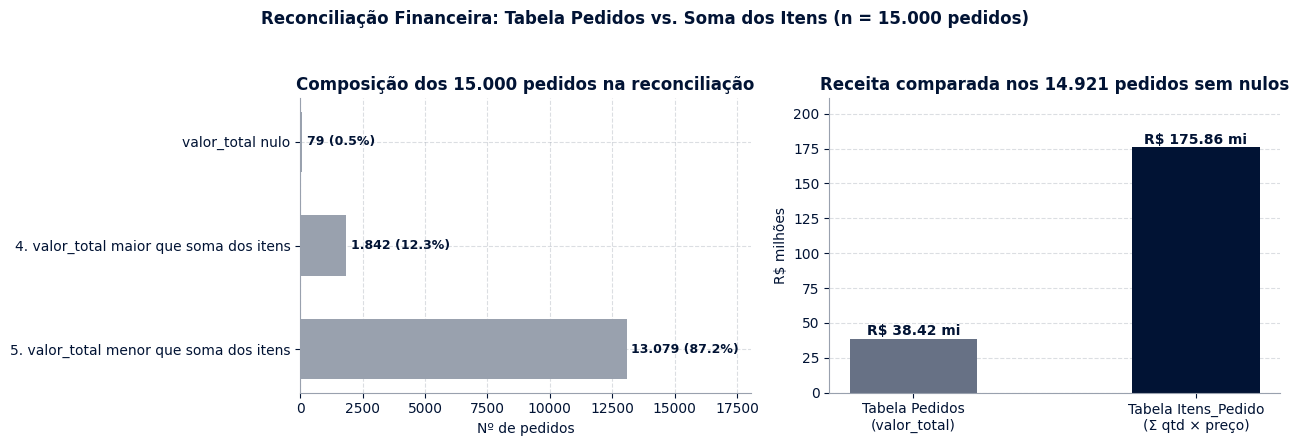

In [61]:
# 1. Verifica se as divergências têm relação com cupom_desconto, status ou canal_venda
rec['divergente'] = rec['abs_diferenca'] > TOL

print('Taxa de divergência (%) por cupom_desconto (entre pedidos sem nulos):')
validos = rec.dropna(subset=['valor_total', 'soma_itens'])
display(
    validos.groupby('cupom_desconto')
    .agg(
        Pedidos=('id', 'count'),
        Pct_Divergente=('divergente', lambda s: round(s.mean() * 100, 1)),
        Dif_Media_R=('diferenca', lambda s: round(s.mean(), 2)),
    )
)

# 2. Gráfico comparativo dos totais financeiros e composição dos pedidos
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Painel 1: Composição dos 15.000 pedidos na reconciliação
labels_curtos = {
    '1. Pedido sem itens registrados': 'Sem itens',
    '2. valor_total nulo (com itens)': 'valor_total nulo',
    '3. Bate exato (diferença ≤ R$ 0,02)': 'Bate exato',
    '4. valor_total MAIOR que soma dos itens': 'Pedidos > Itens',
    '5. valor_total MENOR que soma dos itens': 'Pedidos < Itens',
}
y_labels = [labels_curtos.get(i, i) for i in tab_rec.index]
cores_barras = [
    '#011334' if 'Bate exato' in i else '#99A1AE' for i in tab_rec.index
]

bars1 = axes[0].barh(y_labels, tab_rec['Pedidos'], color=cores_barras, height=0.58)
for b, pct in zip(bars1, tab_rec['% Pedidos']):
  w = b.get_width()
  axes[0].text(
      w + 180,
      b.get_y() + b.get_height() / 2,
      f'{int(w):,} ({pct:.1f}%)'.replace(',', '.'),
      va='center',
      fontsize=9,
      fontweight='bold',
      color='#011334',
  )
axes[0].invert_yaxis()
axes[0].set_title(
    'Composição dos 15.000 pedidos na reconciliação',
    fontweight='bold',
    color='#011334',
)
axes[0].set_xlabel('Nº de pedidos', color='#011334')
axes[0].set_xlim(0, tab_rec['Pedidos'].max() * 1.38)

# Painel 2: Receita total comparada (apenas pedidos sem nulos)
totais_mi = [
    validos['valor_total'].sum() / 1e6,
    validos['soma_itens'].sum() / 1e6,
]
nomes_fontes = ['Tabela Pedidos\n(valor_total)', 'Tabela Itens_Pedido\n(Σ qtd × preço)']
bars2 = axes[1].bar(
    nomes_fontes, totais_mi, color=['#677185', '#011334'], width=0.45
)
for b, v in zip(bars2, totais_mi):
  axes[1].text(
      b.get_x() + b.get_width() / 2,
      v + 0.6,
      f'R$ {v:.2f} mi',
      ha='center',
      va='bottom',
      fontsize=10,
      fontweight='bold',
      color='#011334',
  )
axes[1].set_title(
    f'Receita comparada nos {len(validos):,} pedidos sem nulos'.replace(',', '.'),
    fontweight='bold',
    color='#011334',
)
axes[1].set_ylabel('R$ milhões', color='#011334')
axes[1].set_ylim(0, max(totais_mi) * 1.2)

for ax in axes:
  ax.spines[['top', 'right']].set_visible(False)
  ax.spines[['left', 'bottom']].set_color('#99A1AE')
  ax.tick_params(colors='#011334')
  ax.grid(axis='both' if ax == axes[0] else 'y', linestyle='--', alpha=0.35, color='#99A1AE')
  ax.set_axisbelow(True)

fig.suptitle(
    'Reconciliação Financeira: Tabela Pedidos vs. Soma dos Itens (n = 15.000 pedidos)',
    fontsize=12,
    fontweight='bold',
    color='#011334',
)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig('q6_reconciliacao_valores.png', dpi=150)
plt.show()

Diagnóstico de desacoplamento: razão, correlação e comportamento por tamanho do carrinho:

In [62]:
validos = validos.copy()
validos['razao_ped_itens'] = validos['valor_total'] / validos['soma_itens']

corr = validos['valor_total'].corr(validos['soma_itens'])
r_min = validos['razao_ped_itens'].min()
r_med = validos['razao_ped_itens'].median()
r_max = validos['razao_ped_itens'].max()

print(f'Correlação (valor_total vs. soma_itens): {corr:.2f}')
print(
    f'Razão (valor_total / soma_itens): mín = {r_min:.3f} | '
    f'mediana = {r_med:.2f} | máx = {r_max:.0f}\n'
)

# Compara médias conforme a quantidade de linhas de item no pedido (1 a 6)
por_qtd_itens = (
    validos.groupby('qtd_linhas_item')
    .agg(
        Pedidos=('id', 'count'),
        Valor_Total_Medio=('valor_total', lambda s: round(s.mean(), 0)),
        Soma_Itens_Media=('soma_itens', lambda s: round(s.mean(), 0)),
        Razao_Mediana=('razao_ped_itens', lambda s: round(s.median(), 2)),
    )
)
por_qtd_itens.index = por_qtd_itens.index.astype(int)
por_qtd_itens.index.name = 'Linhas de Item no Pedido'

display(
    por_qtd_itens.style.format({
        'Pedidos': '{:,.0f}',
        'Valor_Total_Medio': 'R$ {:,.0f}',
        'Soma_Itens_Media': 'R$ {:,.0f}',
        'Razao_Mediana': '{:.2f}',
    })
)

Correlação (valor_total vs. soma_itens): -0.01
Razão (valor_total / soma_itens): mín = 0.001 | mediana = 0.16 | máx = 321



,Pedidos,Valor_Total_Medio,Soma_Itens_Media,Razao_Mediana
Linhas de Item no Pedido,,,,
1,"4,408","R$ 2,579","R$ 4,827",0.41
2,"4,533","R$ 2,589","R$ 9,600",0.17
3,"2,999","R$ 2,617","R$ 14,469",0.11
4,"1,440","R$ 2,606","R$ 19,151",0.08
5,926,"R$ 2,425","R$ 24,292",0.06
6,615,"R$ 2,385","R$ 28,625",0.05


### 6.4. Observações e qual número foi escolhido

1. Nenhum pedido bate. Dos 15.000: 79 (0,5%) têm valor_total nulo, 1.842 (12,3%) têm valor_total maior que a soma dos itens e 13.079 (87,2%) menor.
2. A diferença é enorme. valor_total soma R\$ 38,4 mi contra R\$ 175,9 mi nos itens (nos mesmos 14.921 pedidos), ou seja, −78%. Entre os entregues, é R\$ 25,4 mi contra R\$ 118,1 mi.
3. Não é desconto, frete nem imposto. A razão valor_total / soma_itens varia de 0,001 a 321 (mediana de 0,16). A correlação entre as duas colunas é −0,01. E o valor_total médio fica em R\$ 2.400 a R\$ 2.600 quer o pedido tenha 1 item ou 6, enquanto a soma dos itens vai de R$ 4,8 mil a R\$ 28,6 mil. Ou seja, o valor_total não acompanha o que está no carrinho.
4. Como Itens_Pedido é consistente com o catálogo (preço = catálogo × (1 − desconto) em todos os itens), não tem nulos e se relaciona com o tamanho do pedido, ele possui mais integridade do que valor_total que tem nulos e não se relaciona com os itens. Mas o nível absoluto dos itens (R\$ 11,8 mil por pedido) também precisa de validação com o time de financeiro.

## 7. **Q7** - Fornecedores, avaliações e chamados de suporte

Como vamos medir:
* **Satisfação:** `nota` de `Avaliacoes`, ligada ao fornecedor pelo `produto_id`.
* **Problemas no pedido:** chamados de suporte e pedidos cancelados ou devolvidos. Esses dados estão no nível do pedido, então um pedido conta para um fornecedor se tiver pelo menos um item dele.
* **Aumento de chamados:** o pico de chamados no fim de 2023, citado no case.

### 7.1 Checagem de integridade

In [63]:
assert df_produtos['fornecedor'].notna().all(), "Existem produtos sem fornecedor."
assert df_itens_pedido['produto_id'].isin(df_produtos['id']).all(), "Existem itens com produto fora de Produtos."

pares_item = df_itens_pedido[['pedido_id', 'produto_id']].drop_duplicates()
aval_com_item = df_avaliacoes.merge(pares_item, on=['pedido_id', 'produto_id'])
assert len(aval_com_item) == len(df_avaliacoes), "Existem avaliações de produtos que não estão no pedido."

print("Checagens concluídas com sucesso.")
print(f"{df_produtos['fornecedor'].nunique()} fornecedores, {len(df_produtos)} produtos, {len(df_avaliacoes):,} avaliações.")

Checagens concluídas com sucesso.
9 fornecedores, 200 produtos, 8,000 avaliações.


### 7.2 Tabela por fornecedor

In [71]:
produto_forn = df_produtos[['id', 'fornecedor']].rename(columns={'id': 'produto_id'})

# Avaliações
aval = df_avaliacoes.merge(produto_forn, on='produto_id', how='left', validate='many_to_one')

# Pedidos, chamados e cancelamentos (um pedido conta para cada fornecedor presente nele)
itens = df_itens_pedido.merge(produto_forn, on='produto_id', how='left', validate='many_to_one')
pedido_forn = itens[['pedido_id', 'fornecedor']].drop_duplicates()

chamados_pedido = df_tickets_suporte.groupby('pedido_id').size().rename('chamados')
pedidos = (df_pedidos[['id', 'status', 'data_pedido']].rename(columns={'id': 'pedido_id'})
           .merge(chamados_pedido, on='pedido_id', how='left'))
pedidos['chamados'] = pedidos['chamados'].fillna(0)
pedidos['cancel_dev'] = pedidos['status'].isin(['cancelado', 'devolvido'])
pedidos['mes'] = pedidos['data_pedido'].dt.to_period('M')

pf = pedido_forn.merge(pedidos, on='pedido_id')

# Valor dos itens e margem (custo do catálogo)
itens = itens.merge(df_produtos[['id', 'custo_unitario']].rename(columns={'id': 'produto_id'}), on='produto_id')
itens['valor'] = itens['quantidade'] * itens['preco_praticado']
itens['custo'] = itens['quantidade'] * itens['custo_unitario']

tab = pd.concat([
    df_produtos.groupby('fornecedor').size().rename('Produtos'),
    (itens.groupby('fornecedor')['valor'].sum() / itens['valor'].sum() * 100).rename('% do valor dos itens'),
    (1 - itens.groupby('fornecedor')['custo'].sum() / itens.groupby('fornecedor')['valor'].sum()).mul(100).rename('Margem bruta (%)'),
    aval.groupby('fornecedor')['nota'].count().rename('Avaliações'),
    aval.groupby('fornecedor')['nota'].mean().rename('Nota média'),
    aval.groupby('fornecedor')['nota'].apply(lambda s: (s <= 2).mean() * 100).rename('% notas 1-2'),
    pf.groupby('fornecedor').size().rename('Pedidos com o fornecedor'),
    pf.groupby('fornecedor')['chamados'].mean().rename('Chamados por pedido'),
    (pf.groupby('fornecedor')['cancel_dev'].mean() * 100).rename('% cancelado ou devolvido'),
], axis=1).sort_values('Nota média')

tab = tab.round({'% do valor dos itens': 1, 'Margem bruta (%)': 1, 'Nota média': 2, '% notas 1-2': 1,
                 'Chamados por pedido': 3, '% cancelado ou devolvido': 1})
display(tab)

PIOR = tab['Nota média'].idxmin()
print(f"Fornecedor com a menor nota média: {PIOR}")
print(f"Nota média geral: {aval['nota'].mean():.2f} | chamados por pedido (geral): {pedidos['chamados'].mean():.3f}")

,Produtos,% do valor dos itens,Margem bruta (%),Avaliações,Nota média,% notas 1-2,Pedidos com o fornecedor,Chamados por pedido,% cancelado ou devolvido
fornecedor,,,,,,,,,
DeltaFornece ME,24,11.1,44.6,985,2.30,59.9,3872,0.260,24.1
SulFornece SA,22,9.9,37.5,845,3.62,22.4,3644,0.262,25.3
NorteImport Ltda,22,9.8,37.0,824,3.66,22.1,3483,0.266,25.1
TechBrasil Ltda,26,15.0,38.7,1027,3.74,20.3,4265,0.279,24.5
AlphaSupply,17,7.6,40.9,684,3.80,18.1,2855,0.270,25.2
GlobalBR Comércio,22,11.0,37.4,912,3.80,17.4,3569,0.270,24.4
FornecedorX,19,12.1,38.6,789,3.81,18.8,3221,0.274,24.1
MegaDistribuidora,30,15.6,37.7,1241,3.82,17.7,4694,0.259,24.2
MarcoPolo Distribuição,18,8.0,40.4,693,3.84,17.7,3019,0.267,23.8


Fornecedor com a menor nota média: DeltaFornece ME
Nota média geral: 3.58 | chamados por pedido (geral): 0.267


### 7.3 O pior fornecedor é diferente dos demais?

In [72]:
from scipy import stats

nota_pior = aval.loc[aval['fornecedor'] == PIOR, 'nota']
nota_resto = aval.loc[aval['fornecedor'] != PIOR, 'nota']
p_mw = stats.mannwhitneyu(nota_pior, nota_resto).pvalue

# Checa se o problema é generalizado entre os produtos e constante nos trimestres
nota_produto = aval.groupby(['fornecedor', 'produto_id'])['nota'].mean().reset_index()
abaixo = (
    nota_produto.assign(abaixo_de_3=nota_produto['nota'] < 3)
    .groupby('fornecedor')['abaixo_de_3']
    .agg(['sum', 'count'])
)
abaixo.columns = ['Produtos com nota < 3,0', 'Produtos avaliados']

aval_tempo = aval.merge(pedidos[['pedido_id', 'data_pedido']], on='pedido_id')
aval_tempo['trimestre'] = aval_tempo['data_pedido'].dt.to_period('Q')
range_trim = (
    aval_tempo[aval_tempo['fornecedor'] == PIOR]
    .groupby('trimestre')['nota']
    .mean()
)

print(
    f'{PIOR}: nota média {nota_pior.mean():.2f} vs. {nota_resto.mean():.2f} nos demais '
    f'(Mann-Whitney p = {p_mw:.1e}) | faixa trimestral: {range_trim.min():.2f} a {range_trim.max():.2f}'
)
display(
    pd.concat([
        abaixo.loc[[PIOR]],
        abaixo.drop(PIOR).sum().to_frame('Demais 8 fornecedores').T,
    ])
)

DeltaFornece ME: nota média 2.30 vs. 3.76 nos demais (Mann-Whitney p = 3.1e-203) | faixa trimestral: 2.15 a 2.45


,"Produtos com nota < 3,0",Produtos avaliados
DeltaFornece ME,24,24
Demais 8 fornecedores,0,176


### 7.4 Gráfico

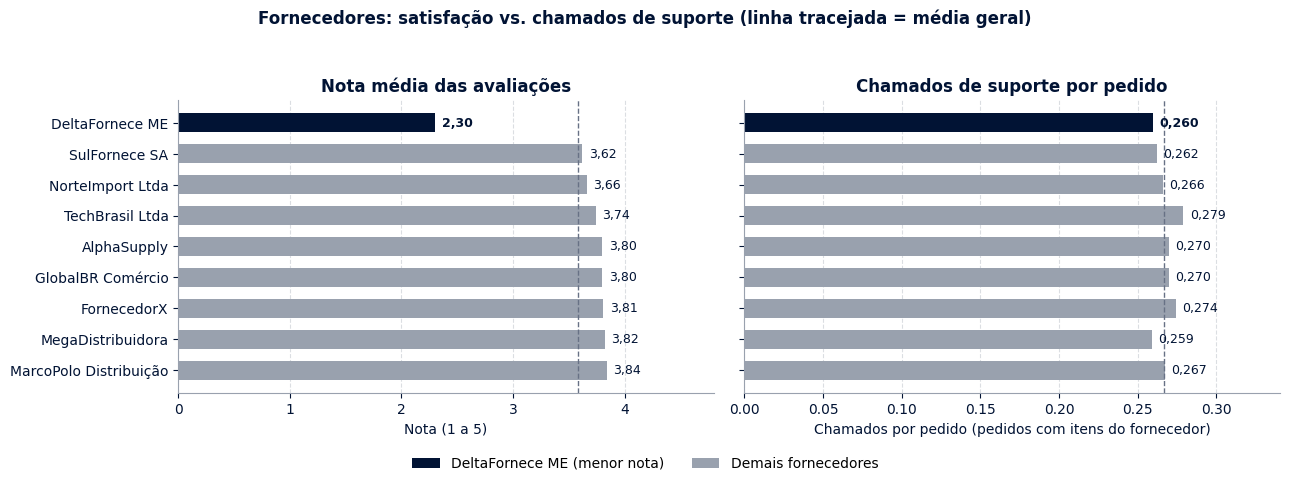

In [73]:
def br(x, casas=0):
  return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


destaque, base_cor = '#011334', '#99A1AE'
cores = [destaque if f == PIOR else base_cor for f in tab.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Painel 1: Nota média
axes[0].barh(tab.index, tab['Nota média'], color=cores, height=0.6)
for y, v in enumerate(tab['Nota média']):
  axes[0].text(
      v + 0.06,
      y,
      br(v, 2),
      va='center',
      fontsize=9,
      fontweight='bold' if tab.index[y] == PIOR else 'normal',
      color='#011334',
  )
axes[0].axvline(aval['nota'].mean(), color='#677185', linestyle='--', linewidth=1)
axes[0].set_title('Nota média das avaliações', fontweight='bold', color='#011334')
axes[0].set_xlabel('Nota (1 a 5)', color='#011334')
axes[0].set_xlim(0, 4.8)

# Painel 2: Chamados por pedido
axes[1].barh(tab.index, tab['Chamados por pedido'], color=cores, height=0.6)
for y, v in enumerate(tab['Chamados por pedido']):
  axes[1].text(
      v + 0.004,
      y,
      br(v, 3),
      va='center',
      fontsize=9,
      fontweight='bold' if tab.index[y] == PIOR else 'normal',
      color='#011334',
  )
axes[1].axvline(pedidos['chamados'].mean(), color='#677185', linestyle='--', linewidth=1)
axes[1].set_title('Chamados de suporte por pedido', fontweight='bold', color='#011334')
axes[1].set_xlabel('Chamados por pedido (pedidos com itens do fornecedor)', color='#011334')
axes[1].set_xlim(0, tab['Chamados por pedido'].max() * 1.22)
axes[1].set_yticklabels([])

for ax in axes:
  ax.invert_yaxis()
  ax.spines[['top', 'right']].set_visible(False)
  ax.spines[['left', 'bottom']].set_color('#99A1AE')
  ax.tick_params(colors='#011334')
  ax.grid(axis='x', linestyle='--', alpha=0.35, color='#99A1AE')
  ax.set_axisbelow(True)

fig.legend(
    handles=[
        Patch(facecolor=destaque, label=f'{PIOR} (menor nota)'),
        Patch(facecolor=base_cor, label='Demais fornecedores'),
    ],
    loc='lower center',
    ncol=2,
    frameon=False,
)
fig.suptitle(
    'Fornecedores: satisfação vs. chamados de suporte (linha tracejada = média geral)',
    fontsize=12,
    fontweight='bold',
    color='#011334',
)
plt.tight_layout(rect=(0, 0.06, 1, 0.94))
plt.savefig('q7_fornecedores.png', dpi=150)
plt.show()

### 7.5 A nota baixa vira mais chamados, cancelamentos ou devoluções?

In [67]:
pedidos['tem_pior'] = pedidos['pedido_id'].isin(pedido_forn.loc[pedido_forn['fornecedor'] == PIOR, 'pedido_id'])
pedidos['tem_chamado'] = pedidos['chamados'] > 0

comparacao = pedidos.groupby('tem_pior').agg(
    Pedidos=('pedido_id', 'count'),
    Chamados_por_pedido=('chamados', 'mean'),
    Pct_cancelado_ou_devolvido=('cancel_dev', lambda s: s.mean() * 100),
).round(3)
comparacao.index = [f'sem itens de {PIOR}', f'com itens de {PIOR}']
display(comparacao)

print(f"Chamados (com vs sem o fornecedor):          p = {stats.chi2_contingency(pd.crosstab(pedidos['tem_pior'], pedidos['tem_chamado']))[1]:.2f}")
print(f"Cancelado/devolvido (com vs sem o fornecedor): p = {stats.chi2_contingency(pd.crosstab(pedidos['tem_pior'], pedidos['cancel_dev']))[1]:.2f}")

chamados_cat = df_tickets_suporte.merge(pedidos[['pedido_id', 'tem_pior']], on='pedido_id')
ct_cat = pd.crosstab(chamados_cat['tem_pior'], chamados_cat['categoria_problema'])
print(f"Categoria dos chamados (com vs sem o fornecedor): p = {stats.chi2_contingency(ct_cat)[1]:.2f}")

# Robustez: só pedidos com itens de um único fornecedor (atribuição sem ambiguidade)
n_forn = pedido_forn.groupby('pedido_id')['fornecedor'].transform('nunique')
unico = pedido_forn[n_forn == 1].merge(pedidos, on='pedido_id')
print(f"\nPedidos de fornecedor único: {len(unico):,} de {len(pedidos):,}")
print('Chamados por pedido, só pedidos de fornecedor único:')
display(unico.groupby('fornecedor')['chamados'].mean().round(3).sort_values().to_frame('Chamados por pedido'))

,Pedidos,Chamados_por_pedido,Pct_cancelado_ou_devolvido
sem itens de DeltaFornece ME,11128,0.269,24.578
com itens de DeltaFornece ME,3872,0.260,24.148


Chamados (com vs sem o fornecedor):          p = 0.29
Cancelado/devolvido (com vs sem o fornecedor): p = 0.61
Categoria dos chamados (com vs sem o fornecedor): p = 0.12

Pedidos de fornecedor único: 4,960 de 15,000
Chamados por pedido, só pedidos de fornecedor único:


,Chamados por pedido
fornecedor,
MegaDistribuidora,0.246
DeltaFornece ME,0.247
SulFornece SA,0.265
NorteImport Ltda,0.271
GlobalBR Comércio,0.273
MarcoPolo Distribuição,0.273
TechBrasil Ltda,0.276
AlphaSupply,0.279
FornecedorX,0.287


### 7.6 O pico de chamados é explicado pelo fornecedor?

In [74]:
chamados = df_tickets_suporte.merge(df_pedidos[['id', 'data_pedido']], left_on='pedido_id', right_on='id', suffixes=('', '_pedido'))
chamados['mes_abertura'] = chamados['data_abertura'].dt.to_period('M')
chamados['dias_ate_abrir'] = (chamados['data_abertura'] - chamados['data_pedido']).dt.days

mensal = pd.DataFrame({
    'Pedidos': pedidos.groupby('mes').size(),
    'Chamados abertos': chamados.groupby('mes_abertura').size(),
})
print('Pedidos e chamados abertos por mês:')
display(mensal.loc['2023-09':'2024-01'].T)
print(f"Mediana mensal de chamados abertos: {mensal['Chamados abertos'].median():.0f} | "
      f"dias entre o pedido e a abertura do chamado: média {chamados['dias_ate_abrir'].mean():.0f}, máximo {chamados['dias_ate_abrir'].max()}")

# Quantos chamados esperaríamos nos pedidos de nov/2023 com a taxa normal?
nov = pedidos['mes'] == pd.Period('2023-11')
taxa_normal = pedidos.loc[~nov, 'chamados'].mean()
print(f"\nPedidos de nov/2023: {nov.sum():,} | chamados observados: {pedidos.loc[nov, 'chamados'].sum():.0f} | "
      f"esperados com a taxa dos outros meses ({taxa_normal:.3f} por pedido): {nov.sum() * taxa_normal:.0f}")

# O perfil dos chamados do pico é diferente?
chamados['pico'] = chamados['mes_abertura'].isin([pd.Period('2023-11'), pd.Period('2023-12')])
chamados['dias_resolucao'] = (chamados['data_resolucao'] - chamados['data_abertura']).dt.days
print('\nChamados abertos em nov-dez/2023 vs demais meses:')
display(chamados.groupby('pico').agg(
    Chamados=('id', 'count'),
    Dias_para_resolver=('dias_resolucao', 'mean'),
).round(1).rename(index={True: 'nov-dez/2023', False: 'demais meses'}))
print(f"Categoria dos chamados (pico vs demais): p = {stats.chi2_contingency(pd.crosstab(chamados['pico'], chamados['categoria_problema']))[1]:.2f}")

Pedidos e chamados abertos por mês:


,2023-09,2023-10,2023-11,2023-12,2024-01
Pedidos,527,554,2317,558,542
Chamados abertos,151,156,375,391,133


Mediana mensal de chamados abertos: 152 | dias entre o pedido e a abertura do chamado: média 15, máximo 30

Pedidos de nov/2023: 2,317 | chamados observados: 603 | esperados com a taxa dos outros meses (0.268 por pedido): 621

Chamados abertos em nov-dez/2023 vs demais meses:


,Chamados,Dias_para_resolver
pico,,
demais meses,3234,7.1
nov-dez/2023,766,7.0


Categoria dos chamados (pico vs demais): p = 0.63


### 7.7. Observações e limitações da base

1. **A DeltaFornece ME apresenta desempenho de satisfação significativamente inferior:** Sua nota média é 2,30 (contra 3,62 a 3,84 nos outros oito fornecedores; Mann-Whitney $p < 10^{-100}$), com 59,9% de avaliações notas 1 ou 2 (vs. 17% a 22% nos demais). O problema é estrutural e permanente: todos os 24 produtos do fornecedor têm média abaixo de 3,0 (nenhum dos outros 176 produtos da loja fica abaixo desse patamar) e a média oscila entre 2,15 e 2,45 em todos os trimestres, sem concentração em um único motivo de reclamação.
2. **A insatisfação não se converte em mais chamados, cancelamentos ou devoluções:** Pedidos com itens da DeltaFornece registram 0,260 chamado/pedido (vs. 0,269 nos demais; $p = 0,29$), 24,1% de cancelamento/devolução (vs. 24,6%; $p = 0,61$) e a mesma distribuição de motivos de ticket ($p = 0,12$). O resultado se mantém ao isolar apenas os 4.960 pedidos de fornecedor único.
3. **O pico de chamados no fim de 2023 decorre do volume de pedidos, não do fornecedor:** A alta de tickets abertos em nov–dez/2023 (375 e 391, ante mediana mensal de 152) acompanha a janela de abertura (até 30 dias) dos 2.317 pedidos de novembro/2023 (Q5), que geraram 603 chamados, mantendo o mesmo perfil de categoria e tempo de resolução.
4. **Implicação executiva (conexão com Q8):** A DeltaFornece ME é um problema real de satisfação do cliente, mas não explica o pico de chamados. Por outro lado, ela responde por 11,1% do valor vendido e entrega a maior margem bruta do portfólio (44,6% vs. 37,0%–40,9%), exigindo cautela antes de um desligamento imediato.

## 8. **Q8** - Priorização executiva

Consolidamos os três principais achados operacionais e financeiros do diagnóstico (Q2–Q7) em uma matriz quantitativa comparando impacto financeiro direto, risco para a rodada Series C e custo de reversão/execução.

### 8.1. Síntese quantitativa das ações candidatas

In [77]:
# Base de itens com receita e margem líquida por pedido
itens_q8 = (
    df_itens_pedido.merge(
        df_produtos[['id', 'fornecedor', 'custo_unitario']].rename(
            columns={'id': 'produto_id'}
        ),
        on='produto_id',
        how='left',
    )
    .assign(
        receita_item=lambda d: d['quantidade'] * d['preco_praticado'],
        custo_item=lambda d: d['quantidade'] * d['custo_unitario'],
    )
)

rec_ped = (
    itens_q8.groupby('pedido_id', as_index=False)
    .agg(receita=('receita_item', 'sum'), custo=('custo_item', 'sum'))
)

ped_q8 = (
    df_pedidos.merge(
        df_clientes[['id', 'canal_aquisicao']].rename(
            columns={'id': 'cliente_id'}
        ),
        on='cliente_id',
        how='left',
    )
    .merge(rec_ped, left_on='id', right_on='pedido_id', how='left')
)

# A: Estancar cancelamentos/gargalo em paid_search + pedidos travados em_transito
ps = ped_q8[ped_q8['canal_aquisicao'] == 'paid_search']
ps_canc = ps[ps['status'] == 'cancelado']
em_trans = ped_q8[ped_q8['status'] == 'em_transito']

rec_ps_perdida = ps_canc['receita'].sum() / 1e6
rec_transito = em_trans['receita'].sum() / 1e6

# B: Desligar fornecedor DeltaFornece ME (Q7)
delta_itens = itens_q8[itens_q8['fornecedor'] == 'DeltaFornece ME']
rec_delta = delta_itens['receita_item'].sum() / 1e6
margem_delta = (
    1 - delta_itens['custo_item'].sum() / delta_itens['receita_item'].sum()
) * 100

# C: Reconciliar Pedidos.valor_total vs. Itens_Pedido (Q6)
validos_q8 = ped_q8.dropna(subset=['valor_total', 'receita'])
gap_rec = (validos_q8['receita'].sum() - validos_q8['valor_total'].sum()) / 1e6

matriz_decisao = pd.DataFrame([
    {
        'Frente Candidata': '1. Auditoria / Trava em paid_search e backlog em_transito (Q2, Q4)',
        'Pedidos Afetados': f"{len(ps_canc) + len(em_trans):,} pedidos",
        'Exposição Financeira (Itens)': f"R$ {rec_ps_perdida + rec_transito:.2f} mi",
        'Efeito Direto no Caixa/Margem': 'Recupera receita perdida e reduz CAC real sem cortar margem',
        'Risco se Postergada': 'Alto (queima contínua de verba de mídia e churn por atraso)',
    },
    {
        'Frente Candidata': '2. Reconciliação contábil Pedidos vs. Itens_Pedido (Q6)',
        'Pedidos Afetados': '15.000 pedidos (100%)',
        'Exposição Financeira (Itens)': f"R$ {gap_rec:.2f} mi (gap)",
        'Efeito Direto no Caixa/Margem': 'Zero efeito operacional imediato (saneamento de dado)',
        'Risco se Postergada': 'Crítico para assinatura da Series C (due diligence)',
    },
    {
        'Frente Candidata': '3. Desligamento imediato da DeltaFornece ME (Q7)',
        'Pedidos Afetados': f"{delta_itens['pedido_id'].nunique():,} pedidos",
        'Exposição Financeira (Itens)': f"R$ {rec_delta:.2f} mi (11,1%)",
        'Efeito Direto no Caixa/Margem': f'Negativo no curto prazo (perde maior margem: {margem_delta:.1f}%)',
        'Risco se Postergada': 'Moderado (nota 2,30, mas sem impacto em chamados/cancelamentos)',
    },
]).set_index('Frente Candidata')

display(matriz_decisao)
print(
    f'Detalhe Frente 1 -> Cancelados paid_search: {len(ps_canc):,} pedidos (R$ {rec_ps_perdida:.2f} mi) | '
    f'Em trânsito: {len(em_trans):,} pedidos (R$ {rec_transito:.2f} mi)'
)

,Pedidos Afetados,Exposição Financeira (Itens),Efeito Direto no Caixa/Margem,Risco se Postergada
Frente Candidata,,,,
"1. Auditoria / Trava em paid_search e backlog em_transito (Q2, Q4)","2,590 pedidos",R$ 30.04 mi,Recupera receita perdida e reduz CAC real sem ...,Alto (queima contínua de verba de mídia e chur...
2. Reconciliação contábil Pedidos vs. Itens_Pedido (Q6),15.000 pedidos (100%),R$ 137.44 mi (gap),Zero efeito operacional imediato (saneamento d...,Crítico para assinatura da Series C (due dilig...
3. Desligamento imediato da DeltaFornece ME (Q7),"3,872 pedidos","R$ 19.64 mi (11,1%)",Negativo no curto prazo (perde maior margem: 4...,"Moderado (nota 2,30, mas sem impacto em chamad..."


Detalhe Frente 1 -> Cancelados paid_search: 1,219 pedidos (R$ 14.10 mi) | Em trânsito: 1,371 pedidos (R$ 15.93 mi)


### 8.2. Comparação visual da exposição financeira por frente (R$ milhões)

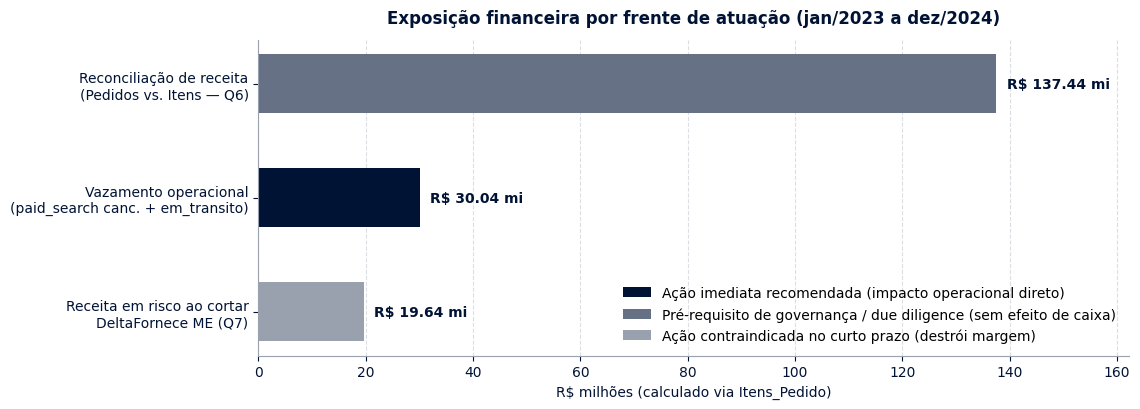

In [76]:
frentes_labels = [
    'Reconciliação de receita\n(Pedidos vs. Itens — Q6)',
    'Vazamento operacional\n(paid_search canc. + em_transito)',
    'Receita em risco ao cortar\nDeltaFornece ME (Q7)',
]
valores_mi = [
    gap_rec,
    rec_ps_perdida + rec_transito,
    rec_delta,
]
cores_q8 = ['#677185', '#011334', '#99A1AE']

fig, ax = plt.subplots(figsize=(11.5, 4.2))
bars = ax.barh(frentes_labels, valores_mi, color=cores_q8, height=0.52)

for b, v in zip(bars, valores_mi):
  ax.text(
      v + 2.0,
      b.get_y() + b.get_height() / 2,
      f'R$ {v:.2f} mi',
      va='center',
      fontsize=10,
      fontweight='bold',
      color='#011334',
  )

ax.invert_yaxis()
ax.set_title(
    'Exposição financeira por frente de atuação (jan/2023 a dez/2024)',
    fontsize=12,
    fontweight='bold',
    color='#011334',
    pad=12,
)
ax.set_xlabel('R$ milhões (calculado via Itens_Pedido)', color='#011334')
ax.set_xlim(0, max(valores_mi) * 1.18)

ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#99A1AE')
ax.tick_params(colors='#011334')
ax.grid(axis='x', linestyle='--', alpha=0.35, color='#99A1AE')
ax.set_axisbelow(True)

ax.legend(
    handles=[
        Patch(facecolor='#011334', label='Ação imediata recomendada (impacto operacional direto)'),
        Patch(facecolor='#677185', label='Pré-requisito de governança / due diligence (sem efeito de caixa)'),
        Patch(facecolor='#99A1AE', label='Ação contraindicada no curto prazo (destrói margem)'),
    ],
    frameon=False,
    loc='lower right',
)

plt.tight_layout()
plt.savefig('q8_acao_imediata.png', dpi=150)
plt.show()

### 8.3. Recomendação ao conselho e o que a empresa deixa de fazer

#### Ação imediata recomendada: Reduzir os cancelamentos do paid_search e destravar os pedidos em_transito
* **O que fazer hoje:** Auditar e corrigir o fluxo de aprovação/pagamento e cumprimento de prazo nos pedidos originados via `paid_search` (que apresenta 30,7% de cancelamento, quase o triplo dos demais canais) e liquidar o passivo de pedidos presos `em_transito` (concentrados sobretudo no 4º trimestre de 2023).
* **Por que esta ação vence em números:**
  * **Impacto financeiro direto e imediato:** Os 1.219 pedidos cancelados em `paid_search` somam R\$ 14,10 milhões em receita perdida, e os 1.371 pedidos travados `em_transito` representam outros R\$ 15,93 milhões em receita sob risco de estorno, totalizando R\$ 30,04 milhões de exposição operacional direta.
  * **Eficiência de capital para a Series C:** Ao reduzir a taxa de cancelamento de `paid_search` (30,7%) para o patamar normal dos demais canais (10%–11%), a OrbitShop converte investimento de marketing já pago em pedidos efetivamente entregues, reduzindo o CAC real e melhorando a geração de caixa sem precisar aumentar o orçamento de mídia.

#### O que a empresa deixa de fazer ao escolher essa ação
Ao concentrar 100% da execução imediata na frente comercial-logística, a empresa adia conscientemente duas outras frentes:
1. **Não substitui nem desliga a fornecedora DeltaFornece ME agora (Q7):** A empresa convive temporariamente com a insatisfação nos 24 SKUs desse fornecedor (nota média 2,30; 59,9% de avaliações 1–2), mas preserva 11,1% da receita bruta e o fornecedor de maior margem bruta do portfólio (44,6% vs. 37,0%–40,9%), evitando uma perda imediata de margem em um problema que comprovadamente não gera chamados nem cancelamentos extras.
2. **Posterga a refatoração definitiva do pipeline de gravação de `Pedidos.valor_total` (Q6):** A investigação e tratamento da divergência de -R$ 137,44 milhões (-78,15%) entre `Pedidos.valor_total` e `Itens_Pedido` fica em segundo plano, mitigado no curto prazo reportando ao conselho e aos investidores exclusivamente os números auditáveis extraídos de `Itens_Pedido` até que a correção seja priorizada futuramente.

## 9. **Q9** - Lacunas dos dados atuais e solicitações ao time de dados

### 9.1. Pergunta central que não conseguimos responder com a base atual
**Qual é a causa raiz real dos cancelamentos no `paid_search` (30,7%) e dos pedidos travados `em_transito` e quanto dessa receita já foi efetivamente liquidada no caixa?**

A base de trabalho mostra onde o vazamento ocorre (1.219 pedidos cancelados em `paid_search` e 1.371 pedidos presos `em_transito`, calculados via `Itens_Pedido`), mas não explica por que esses pedidos falham nem qual foi o desfecho financeiro/logístico de cada um:
* **Ausência de motivo e etapa do cancelamento:** Não sabemos se os cancelamentos de `paid_search` ocorreram antes da aprovação financeira (reprovação de cartão, suspeita de fraude ou *leads* de baixa intenção vindos de mídia paga) ou por desistência/ruptura de estoque após a compra — o que define se a correção está na segmentação de campanhas de *Growth* ou na operação logística.
* **Falta de rastreio e data de entrega:** A tabela `Pedidos` informa apenas o status estático (`em_transito`), sem data de postagem, prazo prometido, transportadora ou última atualização de rastreio — impedindo distinguir pedidos que ainda estão dentro do prazo de pedidos extraviados há meses.
* **Desconexão financeira entre `Pedidos` e `Itens_Pedido`:** Como `Pedidos.valor_total` diverge em -R$ 137,44 milhões (-78,15%) da soma dos itens e não há tabela de pagamentos ou notas fiscais, não é possível confirmar qual valor foi de fato cobrado do cliente, estornado ou liquidado no caixa.

### 9.2. O que pedir ao time de dados e engenharia antes de assinar a recomendação
Para validar o dimensionamento financeiro da recomendação (Q8) e garantir segurança para o conselho e para a rodada *Series C*, solicitaria quatro entregas objetivas:

1. **Tabela de eventos de pagamento e faturamento:** Pedir o histórico de transações aprovadas, recusadas, estornadas e notas fiscais emitidas por `pedido_id` para confirmar qual das duas bases (`Itens_Pedido` = R\$ 176,73 mi vs. `Pedidos.valor_total` = R\$ 38,42 mi) reflete a receita faturada real e auditar a regra de gravação do campo `valor_total` no banco de dados.

2. **Log de transições de status e motivos de cancelamento:** Pedir o histórico com *timestamp* de cada mudança de estado do pedido (`criado` $\rightarrow$ `pago` $\rightarrow$ `enviado` $\rightarrow$ `entregue` / `cancelado`), acompanhado do código ou motivo do cancelamento (falha de pagamento, ruptura de estoque, fraude ou arrependimento), para isolar se os 30,7% de cancelamento do `paid_search` vêm de reprovação no *checkout* (problema de qualidade de tráfego/antifraude) ou de falha pós-compra.

3. **Eventos de rastreamento logístico:** Pedir a data de expedição, transportadora, data prevista de entrega e data da última movimentação para todos os 1.371 pedidos `em_transito`, permitindo separar os pedidos antigos atrasados ou extraviados (que exigem estorno ou reenvio imediato) dos pedidos recentes que ainda estão no fluxo normal de entrega.

4. **Logs de ingestão, migração e origem de registro (`Pedidos` em nov/2023):** Pedir os metadados técnicos de criação dos registros (`created_at` no banco, `batch_id`, sistema de origem ou histórico de cargas e migrações) referentes a outubro–dezembro de 2023, validando se o salto de 2.317 pedidos em novembro/2023, que ocorre de forma uniforme nos 30 dias sem pico específico na Black Friday e replica o perfil de um mês comum, representa vendas reais ou uma falha/carga em lote nos dados.

5. **Investimento detalhado em mídia por canal e campanha (`paid_search`):** Pedir o gasto mensal em aquisição por canal e campanha para calcular o CAC real (custo dividido apenas por clientes com pedidos *entregues*, descontando os 30,7% cancelados) e comprovar ao conselho o retorno financeiro exato da correção.